# 🍊 Orange Vision v4.1: los cuatro modelos de v4 con el dataset *deepFruits orange*

**Objetivo:** repetir el experimento de v4 (YOLOv8n, YOLO11n, YOLOv8m y YOLO11m, cada uno en tres etapas) con **otro dataset de naranjas, mucho más pequeño**:
*deepFruits orange* de Roboflow Universe, con **66 fotos** (v4 usó 1500). Así se responden dos preguntas nuevas:
1. **¿Qué aporta cada etapa cuando hay muy pocas fotos para entrenar?** Aquí solo hay 52 fotos de train; en v4 había 1050.
2. **¿Un modelo entrenado con un dataset funciona con el otro?** Es la generalización entre datasets (sección 5.8 y gráfica G12), y usa los modelos de v4.

| Etapa | Qué es | Entrenamiento con nuestras fotos |
|---|---|---|
| **Pura (COCO)** | El modelo tal como viene, preentrenado en COCO, usando su clase *orange* | Ninguno |
| **Transfer learning** | Backbone congelado; solo se entrenan neck y head (Fase 1) | 30 épocas máx. |
| **Fine-tuning** | Después de la Fase 1, se entrena toda la red con un *learning rate* 10 veces menor (Fase 2) | 30 + 100 épocas máx. |

**Qué cambia respecto a v4**

| | v4 | v4.1 |
|---|---|---|
| Dataset | *Oranges in the field* (Mendeley): 1500 de 5025 fotos, todas de 640 × 640 | *deepFruits orange* (Roboflow): 66 fotos de distintos tamaños |
| División train / val / test | Propia, por ID del árbol: 70 / 10 / 20 % | La oficial de Roboflow: 52 / 7 / 7 fotos |
| Épocas (Fase 1 + Fase 2) | 10 + 40 | 30 + 100 (cada época dura segundos) |
| Batch / `nbs` | 16 / 64 (por defecto) | 8 / 8, para actualizar los pesos en cada iteración (ver 2.3) |
| Paciencia (*early stopping*) | 10 épocas | 30 épocas (el mAP con 7 fotos de validación es muy variable) |
| Sección 5.8 y G12 | Resultados por entorno (mañana, noche, interior…) | Generalización entre datasets: Mendeley ↔ DeepFruits |
| Reutilizar entrenamientos anteriores | Sí (v3) | No: es otro dataset |

Los modelos, los *learning rates*, el aumento de datos, la evaluación y las 15 gráficas son los mismos que en v4, así que los resultados se pueden comparar directamente.

| Sección | Qué se hace | Teoría incluida |
|---|---|---|
| 1. Configuración | Librerías, ajustes, carpetas y estilo de las gráficas | — |
| 2. Datos | Descarga desde Roboflow y división oficial | Conjuntos de datos, por qué un dataset pequeño cambia el entrenamiento (acumulación de gradiente) |
| 3. Teoría y línea base | YOLO de COCO sin entrenar | Redes neuronales, CNN, detección, YOLOv8 vs YOLO11, atención |
| 4. Entrenamiento | Fase 1 (transfer learning) y Fase 2 (fine-tuning) | Funciones de pérdida, *learning rate*, AdamW, sobreajuste, aumento de datos, pura vs transfer learning vs fine-tuning |
| 5. Evaluación | Las 3 etapas en test, matriz de confusión, generalización entre datasets, velocidad | IoU, TP / FP / FN, precisión, recall, F1, AP, mAP, *domain shift*, latencia |
| 6. Gráficas | 15 gráficas, cada una con su explicación | Cómo leer cada gráfica |
| 7. Conclusiones | Resumen automático (con la comparación con v4) y preguntas guía | — |
| 8. Guardar | Modelos y elección del modelo final | Por qué se elige con validación |
| 9. Usar el modelo | Subir una imagen o usar la webcam, **sin volver a entrenar** | — |
| 10. Glosario | Resumen de conceptos y métricas | — |

| Carpeta | Contenido |
|---|---|
| `resultados/v4_1_deepfruits/runs/` | Cada entrenamiento (`f1_…` = Fase 1 = transfer learning, `f2_…` = Fase 2 = fine-tuning) con `weights/best.pt` y `results.csv` |
| `resultados/v4_1_deepfruits/` | Tablas `.csv` y gráficas `.png` (`G1_…` a `G15_…`) |
| `modelos/v4_1/` | Los mejores modelos fine-tuned con DeepFruits (`orange_yolov8n.pt`, …) y `modelos.json`. Los de v3 (`modelos/`) y v4 (`modelos/v4/`) no se tocan |

Las imágenes se descargan en el disco local de Colab (`/content`), que es mucho más rápido que Drive.

**Datasets:**
- Sa, I., Lim, J. Y., Ahn, H. S. y MacDonald, B. (2022). *deepNIR: Datasets for Generating Synthetic NIR Images and Improved Fruit Detection System Using Deep Learning Techniques*. Sensors, 22(13), 4721. https://doi.org/10.3390/s22134721
  Publicado en Roboflow Universe: https://universe.roboflow.com/inkyu-sa-e0c78/deepfruits-orange (versión 2, licencia CC BY 4.0). Las fotos vienen de DeepFruits: Sa, I. et al. (2016), *DeepFruits: A Fruit Detection System Using Deep Neural Networks*, Sensors, 16(8), 1222.
- Para la sección 5.8: Lucas et al., *Oranges in the field*, Mendeley Data, https://doi.org/10.17632/93f32zgkxz.1 (licencia CC BY-NC 3.0).

---
## 1. Configuración

In [6]:
# 1.1 Instalar (si hace falta) e importar librerías
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.175'], check=True)

import gc
import json
import math
import os
import re
import shutil
import time
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Patch
from PIL import Image
from ultralytics import YOLO, settings
from ultralytics.utils.torch_utils import get_flops, get_num_params

settings.update({'tensorboard': False})  # Las curvas se dibujan en la sección 6 a partir de results.csv
print('torch', torch.__version__, '| ultralytics', ultralytics.__version__)

torch 2.14.1+cu130 | ultralytics 8.4.175


In [7]:
# 1.2 Configuración del experimento
PERFIL = 'completo'         # 'rapido': 1 semilla (≈ 30–40 min en T4) | 'completo': 3 semillas (≈ 1.5–2 h; recomendado: con 7 fotos de test el azar pesa mucho)

SEMILLAS = {'rapido': [0], 'completo': [0, 1, 2]}[PERFIL]

# pesos    = modelo preentrenado en COCO: punto de partida del entrenamiento y modelo de la etapa "Pura"
# congelar = capas del backbone que no se entrenan en la Fase 1 (YOLOv8: capas 0-9 → 10; YOLO11: capas 0-10 → 11)
# lr0      = learning rate de la Fase 1: los mismos valores que en v4 (ver 4.2)
MODELOS = {
    'YOLOv8n': {'pesos': 'yolov8n.pt', 'congelar': 10, 'lr0': 1e-3},
    'YOLO11n': {'pesos': 'yolo11n.pt', 'congelar': 11, 'lr0': 1e-3},
    'YOLOv8m': {'pesos': 'yolov8m.pt', 'congelar': 10, 'lr0': 3e-4},
    'YOLO11m': {'pesos': 'yolo11m.pt', 'congelar': 11, 'lr0': 3e-4},
}

EPOCAS_FASE1 = 30   # Fase 1 (transfer learning): backbone congelado
EPOCAS_FASE2 = 100  # Fase 2 (fine-tuning): toda la red, learning rate 10 veces menor
PACIENCIA = 30      # Early stopping: se detiene si mAP50-95 de validación no mejora en estas épocas
IMGSZ = 640         # Las fotos tienen tamaños distintos: Ultralytics las reescala a 640 en el lado mayor
BATCH = 8           # 52 fotos de train → 7 iteraciones por época
NBS = BATCH         # Batch "nominal" de Ultralytics: igual a BATCH = actualizar los pesos en cada iteración (ver 2.3)
OPTIMIZADOR = 'AdamW'

# Aumento de datos, igual que en v4 (ver sección 4.5)
AUMENTACION = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, translate=0.1, scale=0.5, fliplr=0.5, mosaic=1.0)

# Dataset en Roboflow Universe (versión 2 = "deepNIR-more-images", 66 fotos)
ROBOFLOW = dict(workspace='inkyu-sa-e0c78', proyecto='deepfruits-orange', version=2)
ZIP_MANUAL = 'deepfruits-orange.zip'   # Alternativa sin API key: el zip (formato YOLOv8) descargado a mano, en la carpeta del proyecto

# Sección 5.8: cruzar con los modelos de v4 (entrenados con Mendeley) y con el test de Mendeley
EVALUAR_ENTRE_DATASETS = True

In [8]:
# 1.3 Carpetas: resultados y modelos en la carpeta del proyecto (Drive), imágenes en disco local
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PROYECTO = Path('/content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto')
    CARPETA_DATOS = Path('/content/datos_naranjas')
else:
    CARPETA_PROYECTO = Path.cwd()   # La carpeta donde está este notebook
    CARPETA_DATOS = Path.home() / 'datos_naranjas'

if not CARPETA_PROYECTO.exists():
    raise FileNotFoundError(f'No existe {CARPETA_PROYECTO}. Corrige la ruta de CARPETA_PROYECTO.')

NOMBRE_EXPERIMENTO = 'v4_1_deepfruits'
CARPETA_RESULTADOS = CARPETA_PROYECTO / 'resultados' / NOMBRE_EXPERIMENTO
RUNS = CARPETA_RESULTADOS / 'runs'
CARPETA_MODELOS = CARPETA_PROYECTO / 'modelos' / 'v4_1'   # Los modelos de v3 y v4 siguen en modelos/ y modelos/v4/
CARPETA_MODELOS_V4 = CARPETA_PROYECTO / 'modelos' / 'v4'  # Modelos entrenados con Mendeley (solo se leen, sección 5.8)
CARPETA_DATASET = CARPETA_DATOS / NOMBRE_EXPERIMENTO
for carpeta in (RUNS, CARPETA_MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Protección: si cambias ajustes de entrenamiento, no se mezclan con entrenamientos anteriores.
# (PERFIL no cuenta: el perfil 'completo' reutiliza la semilla 0 que ya entrenó el perfil 'rapido'.)
CONFIG = dict(ROBOFLOW=ROBOFLOW, MODELOS=MODELOS, EPOCAS_FASE1=EPOCAS_FASE1, EPOCAS_FASE2=EPOCAS_FASE2, PACIENCIA=PACIENCIA,
              IMGSZ=IMGSZ, BATCH=BATCH, NBS=NBS, OPTIMIZADOR=OPTIMIZADOR, AUMENTACION=AUMENTACION)
ruta_config = CARPETA_RESULTADOS / 'configuracion.json'
if ruta_config.exists() and json.loads(ruta_config.read_text(encoding='utf-8')) != json.loads(json.dumps(CONFIG)):
    raise RuntimeError(f'{ruta_config} tiene otros ajustes. Cambia NOMBRE_EXPERIMENTO (p. ej. "v4_1_deepfruits_b") '
                       'o borra esa carpeta para empezar de cero.')
ruta_config.write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'sin GPU'
print('Perfil:', PERFIL, '| semillas:', SEMILLAS, '| GPU:', GPU)
print('Resultados en:', CARPETA_RESULTADOS)
print('Modelos en:   ', CARPETA_MODELOS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Perfil: completo | semillas: [0, 1, 2] | GPU: Tesla T4
Resultados en: /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/resultados/v4_1_deepfruits
Modelos en:    /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/modelos/v4_1


In [9]:
# 1.4 Funciones de uso general y estilo de las gráficas
ORDEN = list(MODELOS)
ETAPAS = ['Pura (COCO)', 'Transfer learning', 'Fine-tuning']
ETAPA_CORTA = {'Pura (COCO)': 'Pura', 'Transfer learning': 'TL', 'Fine-tuning': 'FT'}
METRICAS = ['Precisión', 'Recall', 'F1', 'mAP50', 'mAP50-95']

# Un color por modelo: el tono indica la generación (azul = YOLOv8, naranja = YOLO11) y la intensidad el tamaño (claro = n, oscuro = m)
COLORES = {'YOLOv8n': '#74B9FF', 'YOLOv8m': '#1F6FB2', 'YOLO11n': '#FF9F43', 'YOLO11m': '#E8503A'}
LINEA = {'YOLOv8n': '--', 'YOLOv8m': '--', 'YOLO11n': '-', 'YOLO11m': '-'}   # En curvas: discontinua = YOLOv8
CAPA = {'YOLOv8n': 3, 'YOLOv8m': 3, 'YOLO11n': 2, 'YOLO11m': 2}             # YOLOv8 (discontinua) encima, para que no la tape YOLO11
# Cuando aparecen las tres etapas, la intensidad del color indica la etapa: pálido = Pura, medio = TL, lleno = FT
ALFA_ETAPA = {'Pura (COCO)': 0.30, 'Transfer learning': 0.60, 'Fine-tuning': 1.0}

# Estética de las gráficas de v1
COLOR_FONDO, COLOR_TEXTO, COLOR_GRID = '#FFF3EB', '#2B1E19', '#F0D5C7'
plt.rcParams.update({
    'figure.facecolor': COLOR_FONDO, 'axes.facecolor': COLOR_FONDO, 'savefig.facecolor': COLOR_FONDO,
    'axes.edgecolor': COLOR_GRID, 'axes.labelcolor': COLOR_TEXTO, 'text.color': COLOR_TEXTO,
    'xtick.color': COLOR_TEXTO, 'ytick.color': COLOR_TEXTO, 'font.size': 9,
    'axes.titleweight': 'bold', 'axes.titlesize': 10.5, 'axes.labelweight': 'bold', 'figure.titleweight': 'bold',
    'axes.grid': True, 'grid.color': COLOR_GRID, 'grid.linestyle': '--', 'grid.alpha': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.facecolor': 'white', 'legend.edgecolor': 'none', 'legend.framealpha': 0.9, 'figure.dpi': 110})


def guardar(fig, nombre):
    """Guarda la figura en la carpeta de resultados y la muestra."""
    fig.savefig(CARPETA_RESULTADOS / nombre, dpi=200, bbox_inches='tight')
    plt.show()


def cargar_modelo(pesos):
    return YOLO(str(pesos))


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def a_rgb(imagen_bgr):
    """OpenCV trabaja en BGR y matplotlib en RGB."""
    return cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

---
## 2. Datos: *deepFruits orange* (Roboflow Universe)

**66 fotos** de naranjos con **una caja por naranja**. Las fotos vienen del dataset **DeepFruits** (Sa et al., 2016) y los autores las publicaron en Roboflow
junto con **deepNIR** (Sa et al., 2022). Se usa la **versión 2** (*deepNIR-more-images*), sin preprocesado ni aumento de datos aplicados en Roboflow.

| | Mendeley (v4) | DeepFruits (v4.1) |
|---|---|---|
| Fotos | 5025 (se usaron 1500) | 66 |
| Tamaño | Todas de 640 × 640 | Distintos tamaños; Ultralytics las reescala a 640 en el lado mayor |
| Condiciones | 9 entornos anotados en el nombre (mañana, noche, interior…) | Sin información de entorno |
| División | Propia, por ID del árbol | La oficial de Roboflow |
| Nombre de la clase | `orange` | `1` (en nuestro `data.yaml` se renombra a `orange`; el número de clase sigue siendo 0) |
| Licencia | CC BY-NC 3.0 | CC BY 4.0 |

Las etiquetas están en el mismo **formato YOLO** que en v4: un archivo `.txt` por foto, con una línea por naranja,
`clase  x_centro  y_centro  ancho  alto`, todo normalizado entre 0 y 1. Al estar normalizadas, sirven para cualquier tamaño de foto.

### Descarga
Roboflow pide una **API key** gratuita: crea una cuenta en roboflow.com y cópiala de *Settings → API Keys*. El notebook la busca en este orden:
1. Un **secreto de Colab** llamado `ROBOFLOW_API_KEY` (icono de la llave 🔑 en el panel izquierdo; activa *Acceso del notebook*).
2. La variable de entorno `ROBOFLOW_API_KEY`.
3. Si no la encuentra, la pide en un cuadro de texto oculto.

**No escribas la API key dentro del notebook:** quedaría guardada en el archivo y en Drive.
**Sin API key:** en la página del dataset elige *Download Dataset → YOLOv8 → Download zip*, renombra el archivo a `deepfruits-orange.zip`
y ponlo en la carpeta del proyecto. Si ese zip existe, el notebook lo usa y no pide nada.

### Train, validación y test
Se usa la **división oficial** de Roboflow: **52 / 7 / 7 fotos** (79 / 11 / 10 %). La ventaja es que cualquiera que use este dataset evalúa con las mismas fotos de test.
La desventaja: **7 fotos de validación y 7 de test son muy pocas**. Una sola foto difícil mueve el mAP varias centésimas, así que:
- las diferencias pequeñas entre modelos (≈ 0.02–0.03 de mAP50-95) **no son concluyentes**;
- el perfil `'completo'` entrena **3 semillas** y las tablas muestran media ± desviación, para ver cuánto cambia el resultado solo por azar.

**Fuga de datos:** este dataset no trae un identificador de árbol ni de sesión, así que no se puede comprobar, como en v4,
que no haya fotos casi iguales repartidas entre train y test. Se confía en la división de los autores.

In [10]:
# 2.1 Funciones para descargar el dataset y ordenarlo con la misma estructura que en v4
CARPETAS_ROBOFLOW = {'train': 'train', 'val': 'valid', 'test': 'test'}   # Nombre en este notebook → nombre en Roboflow
EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp'}


def api_key_roboflow():
    """Busca la API key sin escribirla nunca en el notebook."""
    if EN_COLAB:
        try:
            from google.colab import userdata
            clave = userdata.get('ROBOFLOW_API_KEY')
            if clave:
                return clave
        except Exception:   # El secreto no existe o el notebook no tiene acceso
            pass
    if os.environ.get('ROBOFLOW_API_KEY'):
        return os.environ['ROBOFLOW_API_KEY']
    from getpass import getpass
    return getpass('API key de Roboflow (no se guarda en el notebook): ').strip()


def descargar_roboflow(destino):
    """Deja el dataset (formato YOLOv8) en destino: desde el zip manual si existe, si no con la API de Roboflow."""
    yamls = sorted(destino.rglob('data.yaml'))
    if yamls:
        print(f'Ya descargado en {destino}')
        return yamls[0].parent
    destino.mkdir(parents=True, exist_ok=True)
    zip_manual = CARPETA_PROYECTO / ZIP_MANUAL
    if zip_manual.exists():
        print(f'Descomprimiendo {zip_manual.name} ...')
        with zipfile.ZipFile(zip_manual) as z:
            z.extractall(destino)
    else:
        if importlib.util.find_spec('roboflow') is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'roboflow'], check=True)
        from roboflow import Roboflow
        proyecto = Roboflow(api_key=api_key_roboflow()).workspace(ROBOFLOW['workspace']).project(ROBOFLOW['proyecto'])
        proyecto.version(ROBOFLOW['version']).download('yolov8', location=str(destino), overwrite=True)
    yamls = sorted(destino.rglob('data.yaml'))
    if not yamls:
        raise FileNotFoundError(f'No se encontró data.yaml en {destino}. ¿El zip está en formato YOLOv8?')
    return yamls[0].parent


def ordenar_dataset(origen):
    """Copia fotos y etiquetas a CARPETA_DATASET/images|labels/{train,val,test} (como en v4) y escribe data.yaml."""
    filas = []
    for split, carpeta in CARPETAS_ROBOFLOW.items():
        for tipo in ('images', 'labels'):
            (CARPETA_DATASET / tipo / split).mkdir(parents=True, exist_ok=True)
        for imagen in sorted((origen / carpeta / 'images').iterdir()):
            if imagen.suffix.lower() not in EXTENSIONES:
                continue
            etiqueta = origen / carpeta / 'labels' / (imagen.stem + '.txt')
            for tipo, archivo in (('images', imagen), ('labels', etiqueta)):
                destino = CARPETA_DATASET / tipo / split / archivo.name
                if archivo.exists() and not destino.exists():
                    shutil.copy(archivo, destino)
            with Image.open(imagen) as im:
                ancho, alto = im.size
            filas.append({'archivo': imagen.name, 'split': split, 'ancho': ancho, 'alto': alto})
    ruta_yaml = CARPETA_DATASET / 'data.yaml'
    ruta_yaml.write_text(f'path: {CARPETA_DATASET.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n'
                         'names:\n  0: orange\n', encoding='utf-8')
    return pd.DataFrame(filas), str(ruta_yaml)


def ruta_imagen(archivo, split):
    return CARPETA_DATASET / 'images' / split / archivo


def leer_cajas(archivo, split, ancho=None, alto=None):
    """Cajas reales de una imagen en píxeles: una fila (x1, y1, x2, y2) por naranja.
    Las fotos tienen tamaños distintos: si no se indica, el tamaño se lee de la imagen."""
    if ancho is None or alto is None:
        with Image.open(ruta_imagen(archivo, split)) as im:
            ancho, alto = im.size
    ruta = CARPETA_DATASET / 'labels' / split / (Path(archivo).stem + '.txt')
    lineas = [linea.split() for linea in (ruta.read_text().splitlines() if ruta.exists() else []) if linea.strip()]
    cajas = []
    for valores in lineas:
        v = np.array(valores[1:], dtype=float)
        if len(v) == 4:      # Caja: x_centro, y_centro, ancho, alto
            xc, yc, w, h = v
        else:                # Polígono (x1 y1 x2 y2 …): se usa la caja que lo encierra
            xs, ys = v[0::2], v[1::2]
            xc, yc, w, h = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2, xs.max() - xs.min(), ys.max() - ys.min()
        cajas.append([(xc - w / 2) * ancho, (yc - h / 2) * alto, (xc + w / 2) * ancho, (yc + h / 2) * alto])
    return np.array(cajas).reshape(-1, 4)

In [11]:
# 2.2 Descargar y ordenar
origen = descargar_roboflow(CARPETA_DATOS / 'roboflow_deepfruits_orange')
seleccion, DATA = ordenar_dataset(origen)
clases = {linea.split()[0] for ruta in (CARPETA_DATASET / 'labels').rglob('*.txt')
          for linea in ruta.read_text().splitlines() if linea.strip()}
assert clases <= {'0'}, f'Se esperaba una sola clase (0) y hay: {sorted(clases)}'

# Comprobar que la división es la misma que en ejecuciones anteriores de este experimento
ruta_division = CARPETA_RESULTADOS / 'division.csv'
division = seleccion[['archivo', 'split']]
if ruta_division.exists():
    if not pd.read_csv(ruta_division).equals(division.reset_index(drop=True)):
        raise RuntimeError(f'La división no coincide con {ruta_division}. Usa otro NOMBRE_EXPERIMENTO.')
else:
    division.to_csv(ruta_division, index=False)

seleccion['naranjas'] = [len(leer_cajas(f.archivo, f.split, f.ancho, f.alto)) for f in seleccion.itertuples()]
RESUMEN_DATOS = seleccion.groupby('split').agg(imagenes=('archivo', 'size'), naranjas=('naranjas', 'sum'),
                                               naranjas_por_imagen=('naranjas', 'mean'),
                                               ancho_medio=('ancho', 'mean'), alto_medio=('alto', 'mean'))
display(RESUMEN_DATOS.loc[['train', 'val', 'test']].round(1))
print('Tamaños de foto (ancho × alto):')
display(seleccion.groupby(['ancho', 'alto']).size().rename('fotos').to_frame())

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datos_naranjas/roboflow_deepfruits_orange in yolov8:: 100%|██████████| 144/144 [00:00<00:00, 7840.94it/s]


,imagenes,naranjas,naranjas_por_imagen,ancho_medio,alto_medio
split,,,,,
train,52,271,5.2,635.9,590.2
val,7,33,4.7,515.3,478.7
test,7,55,7.9,571.1,531.9


Tamaños de foto (ancho × alto):


fotos
ancho alto       
333   500       3
334   500       2
375   500       6
378   500       1
379   500       1
400   334       1
      430       1
      600       1
405   500       1
441   500       1
461   500       1
467   350       2
500   333       2
      354       1
      375      16
      397       1
      459       1
      500       1
514   343       1
522   700       1
552   600       1
590   891       1
600   354       1
      600       1
640   428       2
730   1024      1
800   533       1
      600       1
      800       1
900   600       1
1000  648       1
1024  768       2
      1024      1
1200  1600      1
1280  960       1
1355  900       1
1440  2273      1
1600  1200      1
1920  1280      1

### 2.3 Un dataset pequeño cambia el entrenamiento
Con 52 fotos de train hay que revisar tres ajustes que en v4 no importaban.

**1. Acumulación de gradiente (`nbs`).** Ultralytics simula siempre un batch de `nbs = 64` imágenes (*nominal batch size*): si el batch real es menor,
**suma los gradientes de varios batches antes de actualizar los pesos**, cada $\text{acumular} = \text{nbs} / \text{batch}$ iteraciones.
- En v4 (1050 fotos de train, batch 16) había 66 iteraciones por época y se actualizaba cada 4: ≈ 16 actualizaciones por época, sin problema.
- Aquí, con 52 fotos y batch 8, habría 7 iteraciones por época y una actualización cada 8 iteraciones: **menos de una por época**.
  130 épocas serían apenas ≈ 110 pasos de aprendizaje.

Por eso en este notebook `nbs = BATCH`: los pesos se actualizan **en cada iteración** (7 por época). Ultralytics también escala el *weight decay* con `nbs`
($\text{wd} \times \text{batch} \times \text{acumular} / \text{nbs}$); con `nbs = batch` queda igual que el valor por defecto.

**2. Más épocas.** Lo que importa es el número de **actualizaciones de pesos**, no el de épocas. Con 30 + 100 épocas × 7 hay como máximo ≈ 900 actualizaciones,
un número parecido al de v4 (≈ 50 épocas × 16 ≈ 800). Como cada época dura unos segundos, entrenar sigue siendo rápido.

**3. Paciencia y semillas.** Con 7 fotos de validación, el mAP sube y baja mucho de una época a otra; por eso el *early stopping* espera 30 épocas sin mejora (en v4, 10).
Y como el resultado puede depender de la suerte, el perfil `'completo'` repite todo con 3 semillas.

**Riesgo principal: sobreajuste.** Con tan pocas fotos, la red puede **memorizarlas** en lugar de aprender qué es una naranja.
Lo frenan el punto de partida preentrenado (COCO), el aumento de datos (mosaico, volteo, color, escala) y el *early stopping*.
En G6 se ve si la pérdida de validación sube mientras la de train sigue bajando.

In [12]:
# 2.3 Actualizaciones de pesos: nbs = 64 (por defecto) vs nbs = BATCH (este notebook)
n_train = int((seleccion['split'] == 'train').sum())
iteraciones = math.ceil(n_train / BATCH)
filas = []
for nombre, nbs in (('Por defecto (nbs = 64)', 64), (f'Este notebook (nbs = {NBS})', NBS)):
    acumular = max(round(nbs / BATCH), 1)
    filas.append({'Ajuste': nombre, 'Fotos de train': n_train, 'Iteraciones por época': iteraciones,
                  'Acumular (iteraciones)': acumular, 'Actualizaciones por época': iteraciones / acumular,
                  f'Actualizaciones en {EPOCAS_FASE1 + EPOCAS_FASE2} épocas': iteraciones / acumular * (EPOCAS_FASE1 + EPOCAS_FASE2)})
display(pd.DataFrame(filas).set_index('Ajuste').round(1))

,Fotos de train,Iteraciones por época,Acumular (iteraciones),Actualizaciones por época,Actualizaciones en 130 épocas
Ajuste,,,,,
Por defecto (nbs = 64),52,7,8,0.9,113.8
Este notebook (nbs = 8),52,7,1,7.0,910.0


---
## 3. Teoría: de la neurona al detector de objetos

### 3.1 Redes neuronales
Una **neurona artificial** recibe números $x_1, \dots, x_n$, los multiplica por unos **pesos** $w_i$, suma un **sesgo** $b$ y aplica una **función de activación** $f$:

$$y = f\left(\sum_i w_i x_i + b\right)$$

La activación (por ejemplo ReLU: $f(z) = \max(0, z)$) introduce no linealidad; sin ella, muchas capas equivaldrían a una sola.
Una **red neuronal** apila muchas capas de neuronas. Los pesos empiezan con valores aleatorios y el **entrenamiento** consiste en ajustarlos para que la salida sea la correcta.
Cuando la red tiene muchas capas hablamos de ***deep learning*** (aprendizaje profundo).

### 3.2 Redes neuronales convolucionales (CNN)
Una imagen de 640×640 en color son $640 \times 640 \times 3 \approx 1.2$ millones de números. Si cada neurona de la primera capa se conectara a todos ellos,
una sola capa de 1000 neuronas necesitaría 1200 millones de pesos. Las CNN resuelven esto con la **convolución**:

- Un **filtro** (o *kernel*) es una pequeña matriz de pesos, por ejemplo de 3×3, que **se desliza** por toda la imagen.
  En cada posición multiplica sus pesos por los píxeles de debajo y los suma. El resultado es un **mapa de características** (*feature map*).
- El **mismo filtro se usa en toda la imagen** (pesos compartidos): un borde se detecta igual arriba que abajo y se necesitan muy pocos pesos.
- Cada capa aplica decenas o cientos de filtros. Con el *stride* (saltos de 2 píxeles) los mapas se hacen más pequeños y cada neurona "ve" una zona mayor.

Las capas forman una **jerarquía**: las primeras detectan bordes y colores, las intermedias texturas y formas (algo redondo y naranja),
y las profundas objetos completos (una naranja entre hojas). Nadie programa estos filtros: **se aprenden** durante el entrenamiento.

### 3.3 Estructura de un detector: backbone, neck y head
```
 imagen 640x640 ──► BACKBONE ──────────► NECK ─────────────────► HEAD ──────────────► cajas + clase + confianza
                    (extrae               (combina mapas de        (predice dónde están
                    características)       distintos tamaños:       los objetos)
                                           objetos grandes y pequeños)
```
- **Backbone**: la parte "que ve". Convierte la imagen en mapas de características. Es la parte más general y reutilizable.
- **Neck**: mezcla mapas de varias escalas, importante porque hay naranjas cercanas (grandes) y lejanas (pequeñas).
- **Head**: la parte específica de la tarea. Para cada zona predice una caja y una puntuación por clase.

### 3.4 Modelos preentrenados y COCO
Entrenar un backbone desde cero requiere millones de imágenes. Por eso se parte de modelos **preentrenados** en **COCO**,
un dataset de ~118 000 imágenes con 80 clases (personas, coches, perros… y también *orange*).
Sus filtros ya saben detectar bordes, texturas y formas: solo hay que adaptarlos a nuestras naranjas.
En la celda siguiente vemos qué tal lo hace YOLO11n de COCO **sin ningún entrenamiento extra**. Esta es la etapa **Pura**: la **línea base** que el *transfer learning* y el *fine-tuning* deberían superar. En la sección 5 se mide con números para los cuatro modelos.

COCO conoce 80 clases; "orange" es la clase 49.


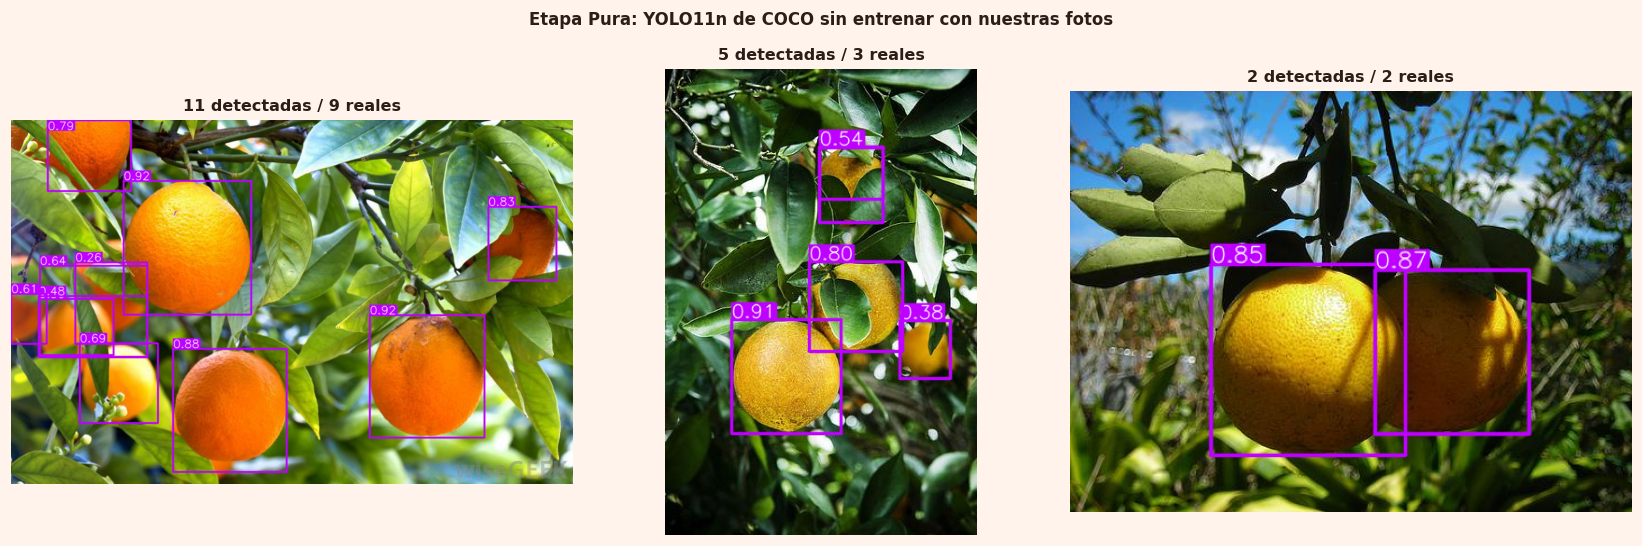

In [13]:
# 3.5 Etapa Pura: YOLO11n preentrenado en COCO, sin entrenar con nuestras imágenes
modelo_coco = YOLO('yolo11n.pt')
ID_NARANJA_COCO = next(k for k, v in modelo_coco.names.items() if v == 'orange')
print(f'COCO conoce {len(modelo_coco.names)} clases; "orange" es la clase {ID_NARANJA_COCO}.')

test_tabla = seleccion[seleccion['split'] == 'test']
ejemplos = test_tabla.sample(min(3, len(test_tabla)), random_state=1)['archivo']
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, archivo in zip(ejes, ejemplos):
    r = modelo_coco.predict(str(ruta_imagen(archivo, 'test')), classes=[ID_NARANJA_COCO], conf=0.25, verbose=False)[0]
    ax.imshow(a_rgb(r.plot(labels=False)))
    ax.set_title(f'{len(r.boxes)} detectadas / {len(leer_cajas(archivo, "test"))} reales')
    ax.axis('off')
plt.suptitle('Etapa Pura: YOLO11n de COCO sin entrenar con nuestras fotos')
plt.tight_layout()
plt.show()

**¿Qué observar?** Compara las naranjas detectadas con las reales. Las fotos de COCO son de naranjas "de mesa", grandes y bien iluminadas;
en el campo hay naranjas pequeñas, tapadas por hojas, verdes o fotografiadas de noche. Esa diferencia entre los datos de origen
y los de destino (*domain shift*) es lo que corrige el **fine-tuning**. También hay *domain shift* entre dos datasets de naranjas de campo (otra cámara, otro huerto, otra luz): se mide en la sección 5.8.

### 3.6 Detección de objetos: conceptos clave
Un detector devuelve, para cada objeto: una **caja** (*bounding box*, $x_1, y_1, x_2, y_2$), una **clase** (aquí solo *orange*) y una **confianza** entre 0 y 1.

**IoU (*Intersection over Union*)** mide cuánto se parecen dos cajas:

$$\text{IoU} = \frac{\text{área de la intersección}}{\text{área de la unión}}$$

IoU = 1 es una coincidencia perfecta y IoU = 0 significa que no se tocan. Una detección se considera correcta si su IoU con una caja real es ≥ 0.5.

**NMS (*Non-Maximum Suppression*)**: los detectores suelen proponer varias cajas para el mismo objeto.
NMS se queda con la de mayor confianza y elimina las que se solapan mucho con ella (IoU alto).

### 3.7 Los cuatro modelos: YOLOv8 y YOLO11
**YOLO (*You Only Look Once*)** es un detector de **una sola etapa**: mira la imagen una vez y, en una sola pasada por la CNN,
predice todas las cajas a la vez. Por eso es muy rápido y se usa en tiempo real.

YOLOv8 (2023) y YOLO11 (2024) son de Ultralytics y comparten las ideas principales:
- ***Anchor-free***: predicen directamente el centro y el tamaño de cada objeto, sin cajas de referencia predefinidas.
- **Head desacoplada**: una rama predice la caja y otra la clase, porque son tareas distintas.
- Necesitan **NMS** al final para quitar cajas duplicadas.

Lo que cambia son los **bloques** con los que se construye la red:

| | YOLOv8 (2023) | YOLO11 (2024) |
|---|---|---|
| Bloque principal | **C2f**: divide los canales, pasa una parte por varias convoluciones y concatena todas las salidas intermedias (el gradiente fluye por muchos caminos) | **C3k2**: versión más ligera de C2f, con convoluciones más pequeñas: menos parámetros para la misma capacidad |
| Final del backbone | **SPPF**: combina el mapa con versiones *max-pooled* de distinto tamaño (contexto a varias escalas) | SPPF + **C2PSA**: un bloque de **atención** que permite a cada zona de la imagen "mirar" al resto |
| Capas del backbone | 10 (capas 0–9) → `congelar = 10` | 11 (capas 0–10) → `congelar = 11` |

**Atención (lo que añade C2PSA).** Los Transformers (2017) nacieron para traducir texto. Su pieza clave es la **atención**:
cada elemento (una palabra, o una zona de la imagen) mira a **todos** los demás y decide cuánto le importa cada uno.

$$\text{Atención}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

$Q$ (*queries*, lo que busco), $K$ (*keys*, lo que ofrece cada elemento) y $V$ (*values*, su contenido) se calculan a partir de los datos.
Una convolución solo mira un vecindario pequeño; la atención relaciona zonas lejanas de la imagen (**contexto global**), por ejemplo
"esta mancha naranja está entre hojas, en la copa de un árbol". YOLO11 la usa en un solo bloque, sobre el mapa más pequeño (20×20), para que el coste siga siendo bajo.

**Tamaños *n* y *m*.** Dentro de cada generación la arquitectura es la misma; cambian dos multiplicadores:
*depth* (cuántas veces se repite cada bloque) y *width* (cuántos filtros tiene cada capa).
- ***n*** (*nano*): el más pequeño y rápido, pensado para dispositivos modestos.
- ***m*** (*medium*): unas 8 veces más parámetros; más preciso, más lento.

| | YOLOv8n | YOLO11n | YOLOv8m | YOLO11m |
|---|---|---|---|---|
| Parámetros (aprox.) | 3.2 M | 2.6 M | 25.9 M | 20.1 M |
| GFLOPs (aprox., 640 px) | 8.7 | 6.5 | 78.9 | 68.0 |
| mAP50-95 en COCO (según Ultralytics) | 37.3 | 39.5 | 50.2 | 51.5 |

*GFLOPs = miles de millones de operaciones para procesar una imagen. En COCO, YOLO11 es algo más preciso con menos parámetros.
La pregunta de este proyecto es si esa ventaja se mantiene con naranjas de campo. Los valores reales de parámetros, GFLOPs y velocidad se miden en la sección 5.8.*

---
## 4. Entrenamiento

### 4.1 Cómo aprende una red
1. La red hace una predicción con sus pesos actuales.
2. La **función de pérdida** (*loss*) mide cuánto se equivoca. En detección hay varias partes:
   - **`box_loss`** (pérdida de caja, basada en **CIoU**): $1 - \text{IoU}$ más dos penalizaciones, por la distancia entre los centros y por la diferencia de proporciones (ancho/alto). Vale 0 si la caja predicha coincide con la real;
   - **`cls_loss`** (pérdida de clase, **entropía cruzada binaria**): castiga una confianza alta donde no hay naranja y una baja donde sí la hay;
   - **`dfl_loss`** (*Distribution Focal Loss*): YOLOv8 y YOLO11 no predicen cada borde como un único número, sino como una **distribución** de posibles distancias. Esta pérdida concentra la distribución en el valor correcto: ajusta la **precisión fina de los bordes**.

   La pérdida total es una suma ponderada: $L = 7.5\,L_{box} + 0.5\,L_{cls} + 1.5\,L_{dfl}$ (pesos por defecto de Ultralytics).
3. **Retropropagación** (*backpropagation*): se calcula el **gradiente**, es decir, en qué dirección cambiar cada peso para que la pérdida baje.
4. **Descenso de gradiente**: se da un pequeño paso en esa dirección: $w \leftarrow w - \eta \, \dfrac{\partial L}{\partial w}$, donde $\eta$ es el *learning rate*.

Vocabulario:
- **Batch**: cuántas imágenes se procesan antes de actualizar los pesos (aquí 8). Más grande = gradiente más estable pero más memoria.
- **Iteración**: una actualización de pesos. Con 52 imágenes de train y batch 8 hay 7 iteraciones por época (ver 2.3).
- **Época**: una pasada completa por todas las imágenes de entrenamiento.

### 4.2 *Learning rate* (tasa de aprendizaje)
Es el tamaño del paso $\eta$. Es el hiperparámetro más importante:
- **Demasiado alto**: los pesos saltan de un lado a otro, la pérdida oscila o explota (`NaN`) y se puede destruir lo aprendido en COCO.
- **Demasiado bajo**: aprende muy despacio y se queda corto en las épocas disponibles.

Para YOLO11 se eligió con un **barrido** en un notebook anterior: 15 épocas de Fase 1 con tres valores, quedándose con el de mejor mAP50-95 **en validación**:

| Modelo | lr = 1e-3 | lr = 3e-4 | lr = 1e-4 | Elegido |
|---|---|---|---|---|
| YOLO11n | **0.412** | 0.398 | 0.378 | 1e-3 |
| YOLO11m | 0.443 | **0.448** | 0.444 | 3e-4 |

Para YOLOv8 **no se repite el barrido** (costaría ≈ 1 h de GPU): se usa el valor del YOLO11 del mismo tamaño. Es una suposición razonable:
misma familia de arquitectura, mismo optimizador y tamaño parecido; además, en el barrido las diferencias entre valores fueron pequeñas (≤ 0.035 de mAP50-95).
Los modelos *m* usan un valor más bajo porque tienen muchos más parámetros: con un paso grande es más fácil estropear lo aprendido en COCO.

En v4.1 se usan **los mismos valores que en v4**: con solo 7 fotos de validación, un barrido no podría distinguir entre ellos de forma fiable, y mantenerlos permite comparar directamente con v4.

Además, el *learning rate* **no es constante**:
- ***Warmup***: las primeras 3 épocas empieza muy bajo y sube poco a poco, para no "romper" la red al principio.
- **Decaimiento**: después baja linealmente hasta el 1 % del valor inicial, para hacer ajustes cada vez más finos.

La gráfica **G4** (sección 6) muestra este calendario real, época a época.

### 4.3 Optimizador AdamW
El optimizador decide cómo dar cada paso. **AdamW** mejora el descenso de gradiente básico:
- usa **momento** (recuerda la dirección de los pasos anteriores, como una bola que rueda);
- adapta el paso **para cada peso** según lo grande que suelan ser sus gradientes;
- aplica ***weight decay***: empuja los pesos hacia valores pequeños, lo que ayuda a no sobreajustar.

### 4.4 Sobreajuste y *early stopping*
**Sobreajuste** (*overfitting*): el modelo memoriza las imágenes de entrenamiento en lugar de aprender a reconocer naranjas.
Se ve cuando la pérdida de **train sigue bajando** pero el mAP de **validación deja de subir** o empieza a bajar.

***Early stopping***: después de cada época se evalúa en validación. Si el mAP50-95 no mejora en `PACIENCIA` épocas seguidas, el entrenamiento se detiene.
Ultralytics guarda dos archivos: `last.pt` (la última época, para continuar si se corta) y **`best.pt`** (la época con mejor validación, la que usamos).

### 4.5 Aumento de datos (*data augmentation*)
En cada época las imágenes de train se modifican al azar, para que el modelo vea más variedad sin descargar más fotos:

| Ajuste | Qué hace | Por qué ayuda con naranjas |
|---|---|---|
| `hsv_h`, `hsv_s`, `hsv_v` | Cambia tono, saturación y brillo | Sol, nubes, noche |
| `translate`, `scale` | Mueve y escala la imagen | Naranjas cerca y lejos |
| `fliplr` | Espejo horizontal (50 %) | Un árbol al revés sigue siendo un árbol |
| `mosaic` | Junta 4 imágenes en una | Más objetos y contextos por imagen |

En las últimas 10 épocas de la Fase 2 se apaga el mosaico (`close_mosaic`), para terminar con imágenes realistas.
Validación y test **nunca** se aumentan.

### 4.6 Pura, *transfer learning* y *fine-tuning*
***Transfer learning*** (aprendizaje por transferencia) es la idea general: reutilizar lo que un modelo aprendió en una tarea (COCO) para otra (naranjas de campo).
Hay varias formas de hacerlo, según **cuánta red se vuelve a entrenar**. Este notebook mide tres puntos de ese camino para cada modelo:

| Etapa | Backbone | Neck y head | *Learning rate* | Épocas máx. | Pesos que se evalúan |
|---|---|---|---|---|---|
| **Pura (COCO)** | De COCO | De COCO (80 clases; se usa *orange*) | — | 0 | `yolo….pt` original |
| **Transfer learning** (Fase 1) | **Congelado** | Se entrenan | `lr0` | 10 | `f1_…/weights/best.pt` |
| **Fine-tuning** (Fase 1 + Fase 2) | Se entrena | Se entrenan | `lr0 / 10` | 10 + 40 | `f2_…/weights/best.pt` |

- **Pura**: no usa ninguna foto nuestra. Mide cuánto "sabe" COCO de naranjas de campo.
- **Transfer learning** en sentido estricto (también llamado *feature extraction*): el backbone se usa como un **extractor de características fijo**
  y solo se aprende a interpretar esas características para nuestras naranjas. Es rápido y seguro, pero los filtros no se adaptan al nuevo dominio
  (hojas, noche, naranjas verdes o pequeñas). La head pasa de 80 clases a 1; Ultralytics conserva la fila de la clase *orange* de COCO como punto de partida.
- ***Fine-tuning***: se **descongela toda la red** y se sigue entrenando con un paso pequeño, para que también los filtros del backbone se ajusten.
  Es otra forma de *transfer learning*, la más completa.

¿Por qué en dos fases y no fine-tuning directamente? Al principio la head nueva da predicciones malas y produce gradientes grandes.
Si el backbone estuviera libre, esos gradientes podrían **borrar** los filtros útiles de COCO (*olvido catastrófico*).
Con el backbone congelado, la head aprende primero a usar esas características (además, es más rápido y usa menos memoria).
En la Fase 2 se descongela todo con un paso 10 veces más pequeño, para **ajustar con suavidad** también los filtros a las naranjas de campo.

Como la Fase 2 parte de los pesos de la Fase 1, el modelo de la Fase 1 **es** el resultado del transfer learning: comparar las tres etapas no cuesta ningún entrenamiento extra.

### 4.7 Semillas y perfiles
La **semilla** fija el azar (orden de las imágenes, aumentos). Con otra semilla el mismo modelo da resultados algo distintos.
- `rapido`: 1 semilla. Suficiente para la demo y para ver tendencias claras.
- `completo`: 3 semillas. Permite dar **media ± desviación**, y saber si la diferencia entre dos modelos es mayor que el "ruido" del azar.

La semilla 0 es la misma en ambos perfiles: si después pasas a `completo`, solo se entrenan las semillas 1 y 2.

### 4.8 Precisión mixta (AMP)
Normalmente cada número usa 32 bits. Con **AMP** (*Automatic Mixed Precision*) muchas operaciones se hacen con 16 bits:
casi el doble de rápido y la mitad de memoria, con prácticamente la misma precisión.

In [14]:
# 4.9 Función de entrenamiento: salta lo terminado y continúa lo interrumpido
def entrenar(nombre_run, pesos, **ajustes):
    carpeta = RUNS / nombre_run
    if (carpeta / 'terminado.txt').exists():
        print(f'✔ Ya entrenado: {nombre_run}')
        return carpeta

    ultimo = carpeta / 'weights' / 'last.pt'
    if ultimo.exists():
        print(f'↻ Continuando: {nombre_run}')
        try:
            cargar_modelo(ultimo).train(resume=True)
        except AssertionError as e:   # Terminó justo antes de marcarse como terminado
            if 'nothing to resume' not in str(e):
                raise
    else:
        print(f'▶ Entrenando: {nombre_run}')
        shutil.rmtree(carpeta, ignore_errors=True)
        cargar_modelo(pesos).train(
            data=DATA, project=str(RUNS), name=nombre_run, exist_ok=True,
            imgsz=IMGSZ, batch=BATCH, nbs=NBS, optimizer=OPTIMIZADOR, amp=True, device=DEVICE, workers=2,
            plots=False, verbose=False, **AUMENTACION, **ajustes)

    (carpeta / 'terminado.txt').write_text('ok')
    liberar_memoria()
    return carpeta

In [15]:
# 4.10 Entrenar los cuatro modelos: Fase 1 = transfer learning (backbone congelado), Fase 2 = fine-tuning (toda la red)
inicio = time.time()
for tipo, cfg in MODELOS.items():
    for semilla in SEMILLAS:
        fase1 = entrenar(f'f1_{tipo}_s{semilla}', cfg['pesos'],
                         epochs=EPOCAS_FASE1, patience=PACIENCIA, lr0=cfg['lr0'], freeze=cfg['congelar'],
                         warmup_epochs=3, close_mosaic=0, seed=semilla)
        entrenar(f'f2_{tipo}_s{semilla}', fase1 / 'weights' / 'best.pt',
                 epochs=EPOCAS_FASE2, patience=PACIENCIA, lr0=cfg['lr0'] / 10, freeze=0,
                 warmup_epochs=0, close_mosaic=10, seed=semilla)
print(f'Entrenamiento completo. Tiempo de esta ejecución: {(time.time() - inicio) / 60:.0f} min')

Se truncaron las últimas líneas 5000 del resultado de transmisión.

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     37/100      1.23G     0.6061      0.424     0.9434         54        640: 100% ━━━━━━━━━━━━ 7/7 8.2it/s 0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.3it/s 0.1s
                   all          7         33       0.88      0.939      0.948      0.803

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     38/100      1.23G     0.6437     0.4344     0.9455         53        640: 100% ━━━━━━━━━━━━ 7/7 8.1it/s 0.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.7it/s 0.1s
                   all          7         33      0.904      0.939      0.951      0.791

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
     39/100      1.23G     0.6311     0

### 4.11 Historial de entrenamiento
Ultralytics guarda en `results.csv` una fila por época con las pérdidas de train y validación, las métricas de validación y el *learning rate*.
Aquí se juntan la Fase 1 y la Fase 2 de cada modelo (semilla 0) en una sola tabla; las gráficas G4 a G7 de la sección 6 salen de aquí.

`best.pt` es la época con **mayor mAP50-95 en validación** de cada fase (es el criterio que usa Ultralytics, su *fitness*).

In [16]:
# 4.11 Leer el historial de entrenamiento (una fila por época)
def leer_resultados(nombre_run):
    df = pd.read_csv(RUNS / nombre_run / 'results.csv')
    df.columns = df.columns.str.strip()
    return df


def historial(tipo, semilla=0):
    """Fase 1 y Fase 2 seguidas, con la fase y la época global (1, 2, …) de cada fila."""
    f1 = leer_resultados(f'f1_{tipo}_s{semilla}').assign(fase=1)
    f2 = leer_resultados(f'f2_{tipo}_s{semilla}').assign(fase=2)
    h = pd.concat([f1, f2], ignore_index=True)
    h['epoca_total'] = np.arange(1, len(h) + 1)
    return h


HISTORIALES = {tipo: historial(tipo, SEMILLAS[0]) for tipo in MODELOS}
display(pd.DataFrame({tipo: {
    'Épocas Fase 1': int((h['fase'] == 1).sum()), 'Épocas Fase 2': int((h['fase'] == 2).sum()),
    'mAP50-95 val (mejor F1)': h.loc[h['fase'] == 1, 'metrics/mAP50-95(B)'].max(),
    'mAP50-95 val (mejor F2)': h.loc[h['fase'] == 2, 'metrics/mAP50-95(B)'].max()} for tipo, h in HISTORIALES.items()}).T.round(3))

,Épocas Fase 1,Épocas Fase 2,mAP50-95 val (mejor F1),mAP50-95 val (mejor F2)
YOLOv8n,30.0,33.0,0.808,0.820
YOLO11n,30.0,67.0,0.780,0.803
YOLOv8m,30.0,42.0,0.829,0.843
YOLO11m,30.0,49.0,0.814,0.843


---
## 5. Evaluación

### 5.1 Aciertos y errores en detección
Con un umbral de IoU (por ejemplo 0.5), cada detección se clasifica así:
- **TP** (verdadero positivo): la detección coincide con una naranja real que aún no estaba emparejada.
- **FP** (falso positivo): detecta una naranja donde no la hay, o repite una ya detectada.
- **FN** (falso negativo): una naranja real que nadie detectó.

No existen los "verdaderos negativos": habría infinitas cajas vacías correctamente ignoradas. Por eso la *accuracy* clásica no se usa en detección.

### 5.2 Métricas
$$\text{Precisión} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

- **Precisión**: de lo que el modelo dice que es naranja, ¿cuánto lo es? (pocas falsas alarmas)
- **Recall**: de las naranjas que hay, ¿cuántas encuentra? (pocas naranjas perdidas)
- **F1**: equilibrio entre ambas (media armónica).

Todas dependen del **umbral de confianza**: con un umbral alto el modelo solo dice "naranja" cuando está muy seguro (más precisión, menos recall); con uno bajo, al revés.

**AP (*Average Precision*)**: se recorre el umbral de confianza de mayor a menor y se dibuja la **curva precisión–recall**. El AP es el área bajo esa curva,
así que resume el modelo **para todos los umbrales a la vez**. Con una sola clase, **mAP** (media de AP entre clases) es simplemente el AP de *orange*.
- **mAP50**: AP con IoU ≥ 0.5. ¿Encuentra las naranjas, aunque la caja no sea exacta?
- **mAP50-95**: media del AP con IoU = 0.50, 0.55, …, 0.95. Premia además que las cajas estén **bien ajustadas**. Es la métrica principal de COCO.

Ultralytics informa la precisión y el recall en el umbral que maximiza F1. El umbral que usaremos para la demo se elige con **validación**.

### 5.3 Reglas de la comparación
- Cada modelo se evalúa en sus **tres etapas**: Pura (pesos de COCO), Transfer learning (`best.pt` de la Fase 1) y Fine-tuning (`best.pt` de la Fase 2).
- Todas las decisiones (mejor semilla, umbral de confianza, modelo final) se toman con **validación**. Test solo se usa para informar.
- El umbral de confianza de cada modelo y etapa es el que maximiza F1 **en validación**.

### 5.4 Tabla de referencia de métricas
| Métrica | Definición | Rango | Mejor | Qué pregunta responde |
|---|---|---|---|---|
| **IoU** | área de la intersección / área de la unión de dos cajas | 0–1 | ↑ | ¿Cuánto se parece la caja predicha a la real? |
| **Precisión** | TP / (TP + FP) | 0–1 | ↑ | De lo que dice que es naranja, ¿cuánto lo es? |
| **Recall** | TP / (TP + FN) | 0–1 | ↑ | De las naranjas reales, ¿cuántas encuentra? |
| **F1** | 2 · P · R / (P + R) | 0–1 | ↑ | Equilibrio entre precisión y recall |
| **Umbral de confianza** | confianza mínima para aceptar una detección | 0–1 | — | Se elige el que maximiza F1 en validación |
| **AP** | área bajo la curva precisión–recall | 0–1 | ↑ | Calidad del modelo para todos los umbrales a la vez |
| **mAP50** | AP con IoU ≥ 0.5 (media entre clases; aquí hay una) | 0–1 | ↑ | ¿Encuentra las naranjas? |
| **mAP50-95** | media del AP con IoU = 0.50, 0.55, …, 0.95 | 0–1 | ↑ | ¿Las encuentra **y** ajusta bien las cajas? **Métrica principal** |
| **box_loss** | pérdida CIoU de las cajas | ≥ 0 | ↓ | ¿Qué tan bien ubica las cajas? |
| **cls_loss** | entropía cruzada binaria de la clase | ≥ 0 | ↓ | ¿Qué tan bien separa naranja de fondo? |
| **dfl_loss** | *Distribution Focal Loss* de los bordes | ≥ 0 | ↓ | ¿Qué tan finos son los bordes de la caja? |
| **Parámetros** | número de pesos, en millones | — | ↓ (a igual precisión) | ¿Cuánta memoria ocupa? |
| **GFLOPs** | miles de millones de operaciones por imagen | — | ↓ | ¿Cuánto cálculo necesita? |
| **Latencia** | ms por imagen (mediana) | — | ↓ | ¿Cuánto tarda en procesar una imagen? |
| **FPS** | 1000 / latencia | — | ↑ | ¿Cuántas imágenes por segundo? (≥ 25–30 = tiempo real) |
| **Épocas / tiempo** | épocas hasta el *early stopping* / minutos de GPU | — | ↓ | ¿Cuánto cuesta entrenarlo? |

### 5.5 Cómo se evalúa la etapa Pura
Los modelos de COCO tienen 80 clases y *orange* es la número 49; nuestras etiquetas usan la clase 0.
Para que Ultralytics los evalúe igual que a los demás, se crea una **copia** de val y test con las etiquetas cambiadas a la clase 49 y un `data.yaml` con los 80 nombres de COCO.
Las otras clases que detecte el modelo (personas, plantas…) no cuentan: el mAP solo se calcula para las clases que aparecen en las etiquetas, es decir, *orange*.

In [17]:
# 5.5 Copia de val y test con las etiquetas en la numeración de COCO (orange = 49)
def copia_en_numeracion_coco(origen, destino, splits):
    """Copia imágenes y etiquetas cambiando la clase 0 por la de orange en COCO. Devuelve la ruta del .yaml (80 clases)."""
    for split in splits:
        (destino / 'images' / split).mkdir(parents=True, exist_ok=True)
        (destino / 'labels' / split).mkdir(parents=True, exist_ok=True)
        for imagen in sorted((origen / 'images' / split).iterdir()):
            if imagen.suffix.lower() not in EXTENSIONES:
                continue
            if not (destino / 'images' / split / imagen.name).exists():
                shutil.copy(imagen, destino / 'images' / split / imagen.name)
            etiqueta = origen / 'labels' / split / (imagen.stem + '.txt')
            lineas = [linea.split() for linea in (etiqueta.read_text().splitlines() if etiqueta.exists() else []) if linea.strip()]
            (destino / 'labels' / split / etiqueta.name).write_text(
                ''.join(f"{ID_NARANJA_COCO} {' '.join(linea[1:])}\n" for linea in lineas), encoding='utf-8')
    nombres_coco = '\n'.join(f'  {k}: {v}' for k, v in modelo_coco.names.items())
    ruta_yaml = destino / 'data.yaml'
    ruta_yaml.write_text(f'path: {destino.as_posix()}\ntrain: images/{splits[0]}\nval: images/{splits[0]}\n'
                         f'test: images/{splits[-1]}\nnames:\n{nombres_coco}\n', encoding='utf-8')
    return str(ruta_yaml)


DATA_COCO = copia_en_numeracion_coco(CARPETA_DATASET, CARPETA_DATOS / f'{NOMBRE_EXPERIMENTO}_coco', ('val', 'test'))
print('Dataset con numeración COCO listo:', DATA_COCO)

Dataset con numeración COCO listo: /content/datos_naranjas/v4_1_deepfruits_coco/data.yaml


### 5.6 Evaluar las tres etapas
Para cada modelo y etapa se calcula todo en **validación** (para elegir el umbral) y en **test** (para informar).
La etapa Pura no depende de la semilla, así que se evalúa una sola vez. Se guardan también las curvas precisión–recall y F1–confianza para las gráficas G9 y G10.

La tabla final tiene **una fila por modelo y etapa** (con varias semillas: media ± desviación), y la segunda tabla resume cuánto mAP50-95 añade cada etapa.

In [18]:
# 5.6 Evaluar en validación y test: 4 modelos × 3 etapas
def evaluar(pesos, split='test', data=None):
    """Métricas de Ultralytics para un modelo en un split, y sus curvas. data permite evaluar en otro .yaml."""
    modelo = cargar_modelo(pesos)
    m = modelo.val(data=data or DATA, split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=False, verbose=False,
                   project=str(CARPETA_RESULTADOS / 'validaciones'), name=split, exist_ok=True)
    p, r = float(m.box.mp), float(m.box.mr)
    curva_f1 = np.asarray(m.box.f1_curve)
    umbral = float(m.box.px[curva_f1.mean(axis=0).argmax()]) if curva_f1.size else 0.25
    curvas = {'eje': np.asarray(m.box.px),                               # 1000 valores entre 0 y 1
              'f1': curva_f1.mean(axis=0),                              # F1 según la confianza
              'pr': np.asarray(m.box.prec_values).mean(axis=0)}         # precisión según el recall (IoU 0.5)
    del modelo
    liberar_memoria()
    metricas = {'Precisión': p, 'Recall': r, 'F1': 2 * p * r / max(p + r, 1e-9),
                'mAP50': float(m.box.map50), 'mAP50-95': float(m.box.map), 'umbral': umbral}
    return metricas, curvas


def pesos_de(tipo, etapa, semilla):
    if etapa == 'Pura (COCO)':
        return MODELOS[tipo]['pesos']
    fase = 'f1' if etapa == 'Transfer learning' else 'f2'
    return RUNS / f'{fase}_{tipo}_s{semilla}' / 'weights' / 'best.pt'


filas, CURVAS = [], {}
for tipo in MODELOS:
    for etapa in ETAPAS:
        for semilla in (SEMILLAS[:1] if etapa == 'Pura (COCO)' else SEMILLAS):
            data = DATA_COCO if etapa == 'Pura (COCO)' else DATA
            pesos = pesos_de(tipo, etapa, semilla)
            val, _ = evaluar(pesos, 'val', data)
            test, CURVAS[(tipo, etapa, semilla)] = evaluar(pesos, 'test', data)
            if etapa == 'Pura (COCO)':
                epocas, minutos = 0, 0.0
            else:
                historia = [leer_resultados(f'f1_{tipo}_s{semilla}')]
                if etapa == 'Fine-tuning':
                    historia.append(leer_resultados(f'f2_{tipo}_s{semilla}'))
                epocas = sum(len(h) for h in historia)
                minutos = sum(h['time'].iloc[-1] for h in historia) / 60
            filas.append({'Modelo': tipo, 'Etapa': etapa, 'Semilla': semilla,
                          **{k: v for k, v in test.items() if k != 'umbral'},
                          'mAP50-95 val': val['mAP50-95'], 'Umbral conf. (val)': val['umbral'],
                          'Épocas': epocas, 'Tiempo (min)': minutos})
por_semilla = pd.DataFrame(filas)
por_semilla.to_csv(CARPETA_RESULTADOS / 'resultados_por_semilla.csv', index=False)

# Mejor semilla de cada modelo fine-tuned: la de mayor mAP50-95 en validación
ft = por_semilla[por_semilla['Etapa'] == 'Fine-tuning']
MEJOR = ft.loc[ft.groupby('Modelo')['mAP50-95 val'].idxmax()].set_index('Modelo').loc[ORDEN]
PESOS_MEJORES = {tipo: pesos_de(tipo, 'Fine-tuning', int(MEJOR.loc[tipo, 'Semilla'])) for tipo in MODELOS}


def semilla_de(tipo, etapa):
    return SEMILLAS[0] if etapa == 'Pura (COCO)' else int(MEJOR.loc[tipo, 'Semilla'])


def fila_de(tipo, etapa):
    """La fila de por_semilla que representa a (modelo, etapa): la mejor semilla del fine-tuning."""
    s = semilla_de(tipo, etapa)
    return por_semilla[(por_semilla['Modelo'] == tipo) & (por_semilla['Etapa'] == etapa) & (por_semilla['Semilla'] == s)].iloc[0]


def media_std(serie):
    return f'{serie.mean():.3f}' if serie.count() < 2 else f'{serie.mean():.3f} ± {serie.std():.3f}'


medias = por_semilla.groupby(['Modelo', 'Etapa'])[METRICAS].mean()
desviaciones = por_semilla.groupby(['Modelo', 'Etapa'])[METRICAS].std().fillna(0)

resumen = por_semilla.groupby(['Modelo', 'Etapa'], sort=False)[METRICAS + ['Épocas', 'Tiempo (min)']].agg(media_std)
resumen.to_csv(CARPETA_RESULTADOS / 'resumen_test.csv')
print(f'Métricas en TEST por modelo y etapa ({len(SEMILLAS)} semilla(s); con varias: media ± desviación)')
display(resumen)

tabla_etapas = medias['mAP50-95'].unstack()[ETAPAS].loc[ORDEN]
tabla_etapas['Ganancia TL (TL − Pura)'] = tabla_etapas['Transfer learning'] - tabla_etapas['Pura (COCO)']
tabla_etapas['Ganancia FT (FT − TL)'] = tabla_etapas['Fine-tuning'] - tabla_etapas['Transfer learning']
tabla_etapas.to_csv(CARPETA_RESULTADOS / 'map50_95_por_etapa.csv')
print('\nmAP50-95 en test por etapa y lo que añade cada una')
display(tabla_etapas.round(3))

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1334.7±197.4 MB/s, size: 40.7 KB)
val: Scanning /content/datos_naranjas/v4_1_deepfruits_coco/labels/val... 7 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 7/7 1.4Kit/s 0.0s
val: New cache created: /content/datos_naranjas/v4_1_deepfruits_coco/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 12.0it/s 0.1s
                   all          7         33      0.849      0.854      0.909      0.674
Speed: 0.4ms preprocess, 4.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1823.2

Precisión         Recall             F1  \
Modelo  Etapa                                                            
YOLOv8n Pura (COCO)                0.764          0.767          0.766   
        Transfer learning  0.776 ± 0.063  0.829 ± 0.070  0.798 ± 0.005   
        Fine-tuning        0.820 ± 0.054  0.808 ± 0.043  0.812 ± 0.016   
YOLO11n Pura (COCO)                0.803          0.739          0.769   
        Transfer learning  0.839 ± 0.071  0.789 ± 0.076  0.809 ± 0.007   
        Fine-tuning        0.825 ± 0.034  0.809 ± 0.037  0.816 ± 0.013   
YOLOv8m Pura (COCO)                0.842          0.678          0.751   
        Transfer learning  0.903 ± 0.053  0.794 ± 0.038  0.843 ± 0.003   
        Fine-tuning        0.865 ± 0.057  0.806 ± 0.028  0.833 ± 0.013   
YOLO11m Pura (COCO)                0.882          0.855          0.868   
        Transfer learning  0.849 ± 0.035  0.841 ± 0.046  0.843 ± 0.006   
        Fine-tuning        0.872 ± 0.039  0.840 ± 0.028  0.855 ± 0.007   

                                   mAP50       mAP50-95           Épocas  \
Modelo  Etapa                                                              
YOLOv8n Pura (COCO)                0.820          0.450            0.000   
        Transfer learning  0.884 ± 0.016  0.605 ± 0.005   30.000 ± 0.000   
        Fine-tuning        0.880 ± 0.033  0.619 ± 0.021  69.333 ± 11.846   
YOLO11n Pura (COCO)                0.821          0.469            0.000   
        Transfer learning  0.884 ± 0.011  0.603 ± 0.026   30.000 ± 0.000   
        Fine-tuning        0.896 ± 0.022  0.617 ± 0.015  77.667 ± 18.148   
YOLOv8m Pura (COCO)                0.826          0.491            0.000   
        Transfer learning  0.883 ± 0.038  0.614 ± 0.028   30.000 ± 0.000   
        Fine-tuning        0.884 ± 0.023  0.607 ± 0.020  73.000 ± 10.536   
YOLO11m Pura (COCO)                0.912          0.536            0.000   
        Transfer learning  0.914 ± 0.019  0.635 ± 0.003   30.000 ± 0.000   
        Fine-tuning        0.935 ± 0.006  0.658 ± 0.019   71.667 ± 8.737   

                            Tiempo (min)  
Modelo  Etapa                             
YOLOv8n Pura (COCO)                0.000  
        Transfer learning  0.676 ± 0.129  
        Fine-tuning        1.575 ± 0.200  
YOLO11n Pura (COCO)                0.000  
        Transfer learning  0.705 ± 0.026  
        Fine-tuning        1.972 ± 0.494  
YOLOv8m Pura (COCO)                0.000  
        Transfer learning  1.574 ± 0.184  
        Fine-tuning        4.562 ± 0.892  
YOLO11m Pura (COCO)                0.000  
        Transfer learning  1.360 ± 0.057  
        Fine-tuning        3.867 ± 0.694


mAP50-95 en test por etapa y lo que añade cada una


Etapa,Pura (COCO),Transfer learning,Fine-tuning,Ganancia TL (TL − Pura),Ganancia FT (FT − TL)
Modelo,,,,,
YOLOv8n,0.450,0.605,0.619,0.155,0.014
YOLO11n,0.469,0.603,0.617,0.134,0.013
YOLOv8m,0.491,0.614,0.607,0.122,-0.007
YOLO11m,0.536,0.635,0.658,0.100,0.023


### 5.7 Matriz de confusión en detección
En clasificación, la matriz de confusión cuenta imágenes. En detección se cuentan **cajas**, con un umbral de confianza (el elegido en validación) y un umbral de IoU (0.5):

| | Predicción: naranja | Predicción: nada (fondo) |
|---|---|---|
| **Real: naranja** | **TP**: naranja detectada | **FN**: naranja no detectada |
| **Real: fondo** | **FP**: falsa alarma | — (TN: no se puede contar) |

La casilla de los verdaderos negativos queda vacía: "fondo correctamente ignorado" serían infinitas cajas posibles. Por eso en detección no se usa la *accuracy*.

**Emparejamiento:** las predicciones de cada imagen se recorren de mayor a menor confianza. Cada una se empareja con la naranja real todavía libre con la que tenga
mayor IoU, si ese IoU es ≥ 0.5 (TP); si no, es un FP. Una naranja real solo se empareja una vez: una segunda caja sobre la misma naranja es un FP (duplicado).
Las naranjas que quedan libres al final son los FN.

La precisión y el recall de esta tabla pueden diferir un poco de los de Ultralytics: aquí se usa el umbral elegido en **validación**,
mientras que Ultralytics informa el umbral que maximiza F1 en el propio conjunto evaluado.

In [19]:
# 5.7 Contar TP, FP y FN en test con el umbral de validación
def iou_matriz(a, b):
    """IoU entre cada caja de a (n×4) y cada caja de b (m×4), en formato x1, y1, x2, y2."""
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    interseccion = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return interseccion / (area_a[:, None] + area_b[None, :] - interseccion + 1e-9)


def contar_aciertos(pesos, umbral, clases=None, iou_min=0.5):
    modelo = cargar_modelo(pesos)
    tp = fp = fn = 0
    for archivo in test_tabla['archivo']:
        reales = leer_cajas(archivo, 'test')
        r = modelo.predict(str(ruta_imagen(archivo, 'test')), conf=umbral, classes=clases, imgsz=IMGSZ,
                           device=DEVICE, verbose=False)[0]
        orden = np.argsort(-r.boxes.conf.cpu().numpy())
        predichas = r.boxes.xyxy.cpu().numpy()[orden]
        libre = np.ones(len(reales), dtype=bool)
        ious = iou_matriz(predichas, reales) if len(predichas) and len(reales) else np.zeros((len(predichas), len(reales)))
        for fila in ious:   # Una fila por predicción, de mayor a menor confianza
            candidatas = np.where(libre, fila, 0.0)
            j = int(candidatas.argmax()) if len(candidatas) else -1
            if j >= 0 and candidatas[j] >= iou_min:
                libre[j] = False
                tp += 1
            else:
                fp += 1
        fn += int(libre.sum())
    del modelo
    liberar_memoria()
    return tp, fp, fn


filas = []
for tipo in MODELOS:
    for etapa in ETAPAS:
        umbral = float(fila_de(tipo, etapa)['Umbral conf. (val)'])
        clases = [ID_NARANJA_COCO] if etapa == 'Pura (COCO)' else None
        tp, fp, fn = contar_aciertos(pesos_de(tipo, etapa, semilla_de(tipo, etapa)), umbral, clases)
        filas.append({'Modelo': tipo, 'Etapa': etapa, 'Umbral': umbral, 'TP': tp, 'FP': fp, 'FN': fn,
                      'Precisión': tp / max(tp + fp, 1), 'Recall': tp / max(tp + fn, 1)})
CONFUSION = pd.DataFrame(filas)
CONFUSION.to_csv(CARPETA_RESULTADOS / 'confusion_test.csv', index=False)
print(f'Naranjas reales en test: {CONFUSION.loc[0, "TP"] + CONFUSION.loc[0, "FN"]}')
display(CONFUSION.set_index(['Modelo', 'Etapa']).round(3))

Naranjas reales en test: 55


Umbral  TP  FP  FN  Precisión  Recall
Modelo  Etapa                                                   
YOLOv8n Pura (COCO)         0.123  42  14  13      0.750   0.764
        Transfer learning   0.516  38   8  17      0.826   0.691
        Fine-tuning         0.642  35   4  20      0.897   0.636
YOLO11n Pura (COCO)         0.405  39   4  16      0.907   0.709
        Transfer learning   0.533  43   8  12      0.843   0.782
        Fine-tuning         0.633  39   4  16      0.907   0.709
YOLOv8m Pura (COCO)         0.611  31   3  24      0.912   0.564
        Transfer learning   0.642  41   5  14      0.891   0.745
        Fine-tuning         0.467  43   7  12      0.860   0.782
YOLO11m Pura (COCO)         0.426  39   4  16      0.907   0.709
        Transfer learning   0.835  31   3  24      0.912   0.564
        Fine-tuning         0.743  41   2  14      0.953   0.745

### 5.8 Generalización entre datasets: Mendeley ↔ DeepFruits
Un modelo puede ser muy bueno en "su" dataset y bastante peor con fotos de otra cámara, otro huerto u otra luz: es el *domain shift*.
Para medirlo se cruzan los dos datasets de naranjas. Para cada uno de los cuatro tipos de modelo:

| Entrenado en ↓ / evaluado en → | Test de Mendeley (v4) | Test de DeepFruits (v4.1) |
|---|---|---|
| Nada: **Pura (COCO)** | Sin entrenar con naranjas de campo | Sin entrenar con naranjas de campo |
| **Mendeley** (fine-tuned en v4, `modelos/v4/`) | En su dominio | **Otro dominio** |
| **DeepFruits** (fine-tuned en este notebook) | **Otro dominio** | En su dominio |

- La **diagonal** ("en su dominio") es el resultado habitual de cada notebook.
- Fuera de la diagonal se ve cuánto **generaliza** lo aprendido. Si el modelo de Mendeley supera a la etapa Pura en DeepFruits, lo aprendido en un huerto sirve en otro.
- Si el modelo de DeepFruits queda **por debajo** de la etapa Pura en Mendeley, con 52 fotos se **especializó** demasiado y perdió parte de lo que sabía (*olvido catastrófico*, sección 4.6).
- La columna de DeepFruits tiene solo **7 fotos**; la de Mendeley, las ≈ 300 fotos de test de v4.

**Requisitos:** haber ejecutado v4 (debe existir `modelos/v4/modelos.json`). Para la columna de Mendeley se descargan **solo las fotos de test de v4**,
según el `division.csv` de v4, así que es exactamente el mismo test que en v4. Si falta algo, esa parte se salta y en la tabla aparece vacía.
La métrica es la misma que en 5.6: mAP50 y mAP50-95 de Ultralytics en test.

In [20]:
# 5.8 Evaluar cada modelo en el test de los dos datasets
API_MENDELEY = 'https://data.mendeley.com/public-api/datasets/93f32zgkxz'
CABECERA = {'User-Agent': 'Mozilla/5.0'}
ORIGENES = ['Pura (COCO)', 'Mendeley (v4)', 'DeepFruits (v4.1)']
TESTS = ['Mendeley', 'DeepFruits']


def descargar(url, destino):
    if destino.exists() and destino.stat().st_size > 0:
        return
    temporal = destino.with_name(destino.name + '.part')
    for intento in range(4):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=CABECERA), timeout=60) as r:
                temporal.write_bytes(r.read())
            temporal.replace(destino)
            return
        except Exception:
            if intento == 3:
                raise
            time.sleep(2 ** intento)


def leer_info_v4():
    ruta = CARPETA_MODELOS_V4 / 'modelos.json'
    if not ruta.exists():
        print(f'No se encontró {ruta}: ejecuta v4 para tener los modelos entrenados con Mendeley.')
        return None
    return json.loads(ruta.read_text(encoding='utf-8'))


def preparar_test_mendeley(info_v4):
    """Descarga las fotos de test de v4 y devuelve dos .yaml: clase orange (modelos entrenados) y numeración COCO (Pura)."""
    ruta_division_v4 = CARPETA_PROYECTO / 'resultados' / info_v4['experimento'] / 'division.csv'
    if not ruta_division_v4.exists():
        print(f'No se encontró {ruta_division_v4}: se salta el test de Mendeley.')
        return None
    test_v4 = pd.read_csv(ruta_division_v4).query("split == 'test'")['archivo']
    try:
        with urllib.request.urlopen(urllib.request.Request(API_MENDELEY, headers=CABECERA), timeout=60) as r:
            urls = {a['filename']: a['content_details']['download_url'] for a in json.loads(r.read().decode('utf-8'))['files']}
        carpeta = CARPETA_DATOS / 'mendeley_test_v4'
        trabajos = []
        for archivo in test_v4:
            etiqueta = archivo[:-4] + '.txt'
            trabajos += [(urls[archivo], carpeta / 'images' / 'test' / archivo), (urls[etiqueta], carpeta / 'labels' / 'test' / etiqueta)]
        for tipo in ('images', 'labels'):
            (carpeta / tipo / 'test').mkdir(parents=True, exist_ok=True)
        print(f'Descargando las {len(test_v4)} fotos de test de Mendeley (v4) ...')
        with ThreadPoolExecutor(max_workers=8) as pool:
            list(pool.map(lambda t: descargar(*t), trabajos))
    except Exception as e:   # Sin internet, la API cambió, etc.
        print(f'No se pudo descargar el test de Mendeley ({e}): se salta esa columna.')
        return None
    ruta_yaml = carpeta / 'data.yaml'
    ruta_yaml.write_text(f'path: {carpeta.as_posix()}\ntrain: images/test\nval: images/test\ntest: images/test\n'
                         'names:\n  0: orange\n', encoding='utf-8')
    return {'orange': str(ruta_yaml), 'coco': copia_en_numeracion_coco(carpeta, CARPETA_DATOS / 'mendeley_test_v4_coco', ('test',))}


INFO_V4 = leer_info_v4() if EVALUAR_ENTRE_DATASETS else None
DATA_MENDELEY = preparar_test_mendeley(INFO_V4) if INFO_V4 else None

filas = []
for tipo in ORDEN:
    pesos_v4 = CARPETA_MODELOS_V4 / INFO_V4['modelos'][tipo]['archivo'] if INFO_V4 and tipo in INFO_V4['modelos'] else None
    for origen in ORIGENES:
        for test in TESTS:
            fila = {'Modelo': tipo, 'Entrenado en': origen, 'Test': test, 'mAP50': np.nan, 'mAP50-95': np.nan}
            if test == 'DeepFruits' and origen != 'Mendeley (v4)':   # Ya medido en 5.6
                r = fila_de(tipo, 'Pura (COCO)' if origen == 'Pura (COCO)' else 'Fine-tuning')
            elif test == 'DeepFruits' and pesos_v4 and pesos_v4.exists():
                r, _ = evaluar(pesos_v4, 'test', DATA)
            elif test == 'Mendeley' and DATA_MENDELEY:
                pesos = {'Pura (COCO)': MODELOS[tipo]['pesos'], 'Mendeley (v4)': pesos_v4, 'DeepFruits (v4.1)': PESOS_MEJORES[tipo]}[origen]
                if pesos is None or not Path(pesos).exists() and origen != 'Pura (COCO)':
                    filas.append(fila)
                    continue
                r, _ = evaluar(pesos, 'test', DATA_MENDELEY['coco' if origen == 'Pura (COCO)' else 'orange'])
            else:
                filas.append(fila)
                continue
            fila.update({'mAP50': float(r['mAP50']), 'mAP50-95': float(r['mAP50-95'])})
            filas.append(fila)
GENERALIZACION = pd.DataFrame(filas)
GENERALIZACION.to_csv(CARPETA_RESULTADOS / 'generalizacion_entre_datasets.csv', index=False)
tabla_generalizacion = (GENERALIZACION.set_index(['Modelo', 'Entrenado en', 'Test'])['mAP50-95'].unstack('Test')
                        .reindex(index=pd.MultiIndex.from_product([ORDEN, ORIGENES]), columns=TESTS))
print('mAP50-95 en test según con qué se entrenó (filas) y dónde se evalúa (columnas). Vacío = no disponible.')
display(tabla_generalizacion.round(3))

# Comprobación: el modelo de Mendeley en el test de Mendeley debe dar lo mismo que en v4
if INFO_V4 and DATA_MENDELEY:
    for tipo in ORDEN:
        if tipo in INFO_V4['modelos']:
            print(f"{tipo}: mAP50-95 Mendeley→Mendeley = {tabla_generalizacion.loc[(tipo, 'Mendeley (v4)'), 'Mendeley']:.4f} "
                  f"(en v4: {INFO_V4['modelos'][tipo]['mAP50-95 test']:.4f})")

Descargando las 300 fotos de test de Mendeley (v4) ...
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2536.9±859.6 MB/s, size: 132.7 KB)
val: Scanning /content/datos_naranjas/mendeley_test_v4_coco/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 2.0Kit/s 0.1s
val: /content/datos_naranjas/mendeley_test_v4_coco/images/test/MS141_2025-01-20_00.jpg: 1 duplicate labels removed
val: /content/datos_naranjas/mendeley_test_v4_coco/images/test/MS141_2025-01-20_01.jpg: 1 duplicate labels removed
val: New cache created: /content/datos_naranjas/mendeley_test_v4_coco/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 12.7it/s 3.0s
                   all        300       3152      0.731       0.41      0.496      0.222
Speed:

Test                       Mendeley  DeepFruits
YOLOv8n Pura (COCO)           0.222       0.450
        Mendeley (v4)         0.416       0.580
        DeepFruits (v4.1)     0.202       0.609
YOLO11n Pura (COCO)           0.227       0.469
        Mendeley (v4)         0.424       0.548
        DeepFruits (v4.1)     0.206       0.616
YOLOv8m Pura (COCO)           0.270       0.491
        Mendeley (v4)         0.437       0.558
        DeepFruits (v4.1)     0.180       0.621
YOLO11m Pura (COCO)           0.274       0.536
        Mendeley (v4)         0.440       0.603
        DeepFruits (v4.1)     0.198       0.660

YOLOv8n: mAP50-95 Mendeley→Mendeley = 0.4163 (en v4: 0.4163)
YOLO11n: mAP50-95 Mendeley→Mendeley = 0.4243 (en v4: 0.4243)
YOLOv8m: mAP50-95 Mendeley→Mendeley = 0.4365 (en v4: 0.4365)
YOLO11m: mAP50-95 Mendeley→Mendeley = 0.4403 (en v4: 0.4403)


### 5.9 Tamaño y velocidad
Se mide con los modelos fine-tuned: las tres etapas de un modelo tienen la misma arquitectura y prácticamente la misma velocidad.

- **Bloques**: módulos de la red (backbone + neck + head); las primeras `congelar` forman el backbone.
- **Parámetros**: número de pesos del modelo. Más parámetros = más capacidad, pero más memoria.
- **GFLOPs**: operaciones necesarias para procesar una imagen. Indica el coste de cálculo.
- **Latencia**: milisegundos que tarda en procesar una imagen (incluye preparar la imagen y, en YOLO, el NMS). Se toma la **mediana**, que no se ve afectada por tiempos raros.
- **FPS** (*frames per second*) = 1000 / latencia. Para tiempo real se suele pedir ≥ 25–30 FPS.

La latencia se mide con las fotos de los tres conjuntos (test solo tiene 7). Aunque tengan tamaños distintos, todas se reescalan a 640 antes de entrar en la red.

Antes de medir se hacen unas inferencias de **calentamiento**: las primeras siempre son lentas porque se reserva memoria y se preparan los cálculos.

In [21]:
# 5.9 Medir tamaño y latencia (GPU y CPU)
def latencia_ms(modelo, imagenes, dispositivo, n):
    for imagen in imagenes[:5]:   # Calentamiento
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
    tiempos = []
    for imagen in imagenes[:n]:
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return float(np.median(tiempos))


imagenes_test = [cv2.imread(str(ruta_imagen(f.archivo, f.split))) for f in seleccion.head(60).itertuples()]   # Todas las fotos: test solo tiene 7
filas = []
for tipo, pesos in PESOS_MEJORES.items():
    red = cargar_modelo(pesos).model
    fila = {'Modelo': tipo, 'Bloques': len(red.model), 'Backbone': MODELOS[tipo]['congelar'], 'Parámetros (M)': get_num_params(red) / 1e6, 'GFLOPs': get_flops(red, IMGSZ),
            'Archivo (MB)': pesos.stat().st_size / 1e6}
    if torch.cuda.is_available():   # Un modelo recién cargado por dispositivo
        fila['GPU (ms/img)'] = latencia_ms(cargar_modelo(pesos), imagenes_test, DEVICE, 60)
        fila['GPU (FPS)'] = 1000 / fila['GPU (ms/img)']
    fila['CPU (ms/img)'] = latencia_ms(cargar_modelo(pesos), imagenes_test, 'cpu', 20)
    fila['CPU (FPS)'] = 1000 / fila['CPU (ms/img)']
    filas.append(fila)
    liberar_memoria()
velocidad = pd.DataFrame(filas).set_index('Modelo')
velocidad['GPU usada'] = GPU
velocidad.to_csv(CARPETA_RESULTADOS / 'tamano_y_velocidad.csv')
display(velocidad.round(1))

,Bloques,Backbone,Parámetros (M),GFLOPs,Archivo (MB),GPU (ms/img),GPU (FPS),CPU (ms/img),CPU (FPS),GPU usada
Modelo,,,,,,,,,,
YOLOv8n,23,10,3.1,8.7,6.5,9.8,102.4,89.4,11.2,Tesla T4
YOLO11n,24,11,2.6,6.6,5.5,11.8,84.7,105.7,9.5,Tesla T4
YOLOv8m,23,10,25.9,79.1,52.0,22.3,44.8,557.4,1.8,Tesla T4
YOLO11m,24,11,20.1,68.3,40.5,21.9,45.7,643.1,1.6,Tesla T4


---
## 6. Gráficas
Cada gráfica va precedida de una explicación: **qué muestra**, **cómo leerla** y **qué buscar**.
**Todos los números salen de los entrenamientos y evaluaciones de este notebook**; nada se escribe a mano.
Las gráficas se guardan como `.png` en `resultados/v4_1_deepfruits/`.

**Colores:** azul = YOLOv8, naranja = YOLO11; claro = *nano*, oscuro = *medium*. En las curvas, línea discontinua = YOLOv8 y continua = YOLO11.
Cuando aparecen las tres etapas, la intensidad indica la etapa: **pálido = Pura**, **medio = Transfer learning**, **lleno = Fine-tuning**.

| Gráfica | Tema | Gráfica | Tema |
|---|---|---|---|
| G1 | Métricas en test por modelo y etapa | G9 | Curvas precisión–recall y F1–confianza |
| G2 | Progresión Pura → TL → FT | G10 | Curvas precisión–recall por etapa |
| G3 | Comparación final (fine-tuning) | G11 | Velocidad vs precisión |
| G4 | *Learning rate* por época | G12 | Generalización entre datasets |
| G5 | mAP en validación por época | G13 | Estructura de los modelos |
| G6 | Pérdidas de train y validación | G14 | Detecciones de los cuatro modelos |
| G7 | Pérdidas finales de validación | G15 | Detecciones en las tres etapas |
| G8 | Matrices de confusión | | |

### G1. Métricas en test por modelo y etapa
**Qué muestra:** cinco paneles, uno por métrica (precisión, recall, F1, mAP50, mAP50-95). En cada panel hay un grupo de tres barras por modelo: Pura, Transfer learning y Fine-tuning.

**Cómo leerla:** dentro de cada grupo, la altura debería crecer de izquierda a derecha. Entre grupos se comparan los modelos en la misma etapa.
Con varias semillas, la línea negra sobre cada barra es la desviación entre semillas.

**Qué buscar:** ¿cuánto falla la etapa Pura (*domain shift*: las naranjas de COCO no se parecen a las de campo)? ¿Qué parte de la mejora llega ya con el transfer learning?
¿El fine-tuning añade algo más? ¿Mejora más el recall o la precisión?

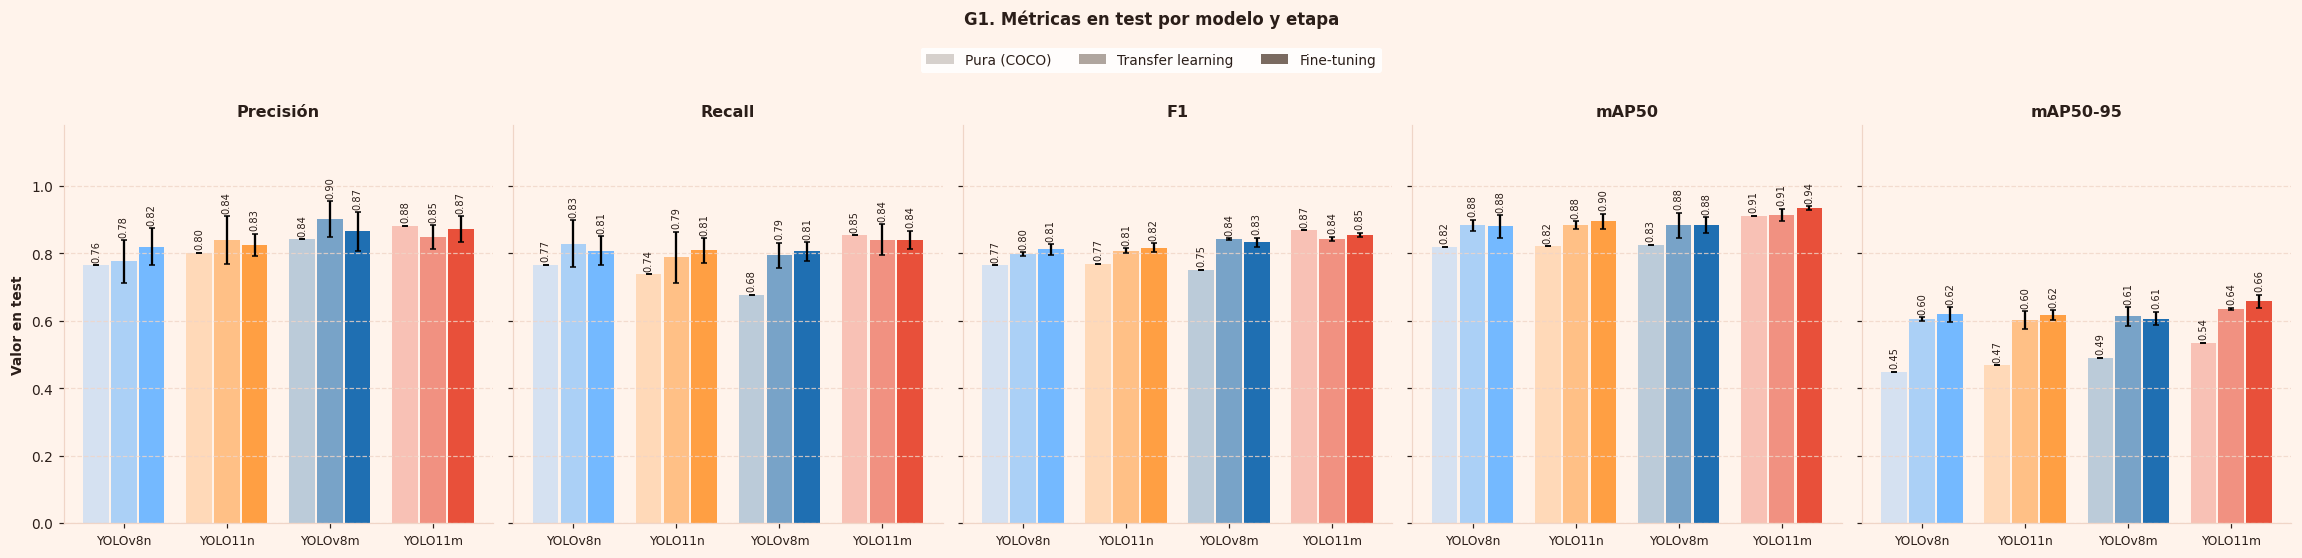

In [22]:
# G1. Métricas en test: 4 modelos × 3 etapas
fig, ejes = plt.subplots(1, len(METRICAS), figsize=(21, 4.6), sharey=True)
x = np.arange(len(ORDEN))
ancho = 0.27
for ax, metrica in zip(ejes, METRICAS):
    for k, etapa in enumerate(ETAPAS):
        barras = ax.bar(x + (k - 1) * ancho, [medias.loc[(t, etapa), metrica] for t in ORDEN], ancho * 0.92,
                        yerr=[desviaciones.loc[(t, etapa), metrica] for t in ORDEN] if len(SEMILLAS) > 1 else None, capsize=2,
                        color=[COLORES[t] for t in ORDEN], alpha=ALFA_ETAPA[etapa])
        ax.bar_label(barras, fmt='%.2f', fontsize=6.5, padding=2, rotation=90)
    ax.set_xticks(x, ORDEN, fontsize=8)
    ax.set_title(metrica)
    ax.set_ylim(0, 1.18)
    ax.grid(axis='x', visible=False)
ejes[0].set_ylabel('Valor en test')
fig.legend(handles=[Patch(facecolor='#7a6a60', alpha=ALFA_ETAPA[e], label=e) for e in ETAPAS],
           loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.suptitle('G1. Métricas en test por modelo y etapa', y=1.09)
plt.tight_layout()
guardar(fig, 'G1_metricas_por_etapa.png')

### G2. Progresión Pura → Transfer learning → Fine-tuning
**Qué muestra:** el mAP50 (izquierda) y el mAP50-95 (derecha) en test de cada modelo al pasar por las tres etapas. Cada línea es un modelo; el número de la derecha es su valor final.

**Cómo leerla:** la pendiente de cada tramo es lo que aporta esa etapa. Un tramo casi plano significa que esa etapa añade poco.

**Qué buscar:** si las líneas se cruzan (un modelo que empieza peor y termina mejor) y si la distancia entre mAP50 y mAP50-95 cambia:
el mAP50-95 sube más cuando las cajas se ajustan mejor a los bordes de las naranjas, algo que sobre todo aporta el fine-tuning.

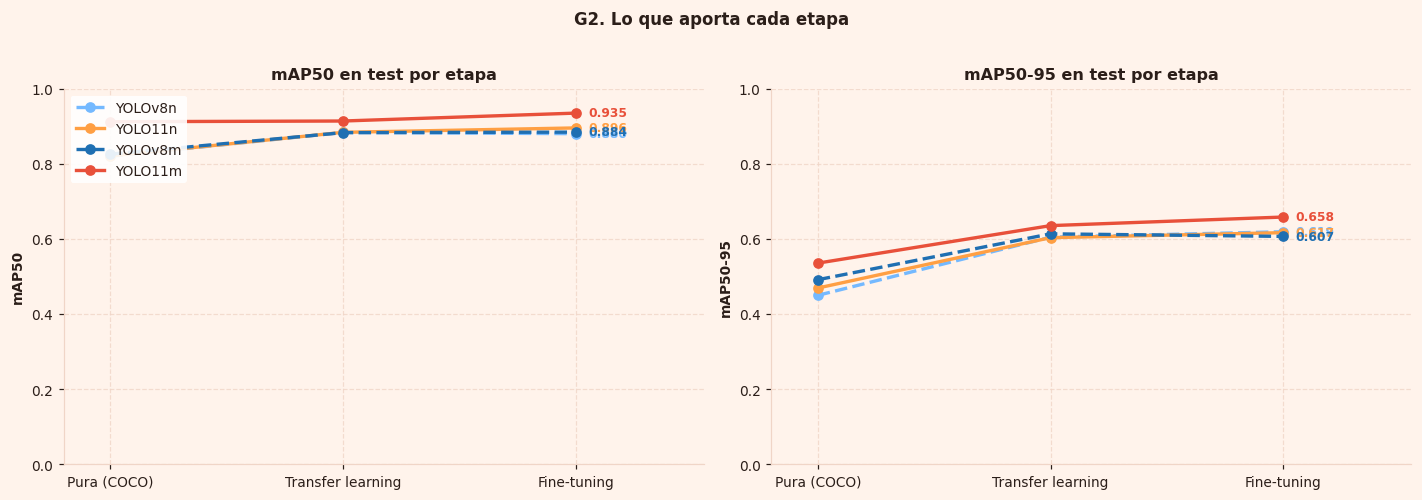

In [23]:
# G2. Progresión por etapas
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, metrica in zip(ejes, ['mAP50', 'mAP50-95']):
    for tipo in ORDEN:
        valores = [medias.loc[(tipo, e), metrica] for e in ETAPAS]
        ax.plot(range(len(ETAPAS)), valores, marker='o', lw=2.2, ls=LINEA[tipo], color=COLORES[tipo], label=tipo)
        ax.annotate(f'{valores[-1]:.3f}', (len(ETAPAS) - 1, valores[-1]), xytext=(8, 0), textcoords='offset points',
                    va='center', fontsize=8, fontweight='bold', color=COLORES[tipo])
    ax.set_xticks(range(len(ETAPAS)), ETAPAS)
    ax.set_xlim(-0.2, len(ETAPAS) - 0.45)
    ax.set_ylim(0, 1)
    ax.set(title=f'{metrica} en test por etapa', ylabel=metrica)
ejes[0].legend(loc='upper left')
fig.suptitle('G2. Lo que aporta cada etapa', y=1.02)
plt.tight_layout()
guardar(fig, 'G2_progresion_etapas.png')

### G3. Comparación final: los cuatro modelos fine-tuned
**Qué muestra:** la comparación principal del proyecto, con el estilo de la gráfica de v1: las cinco métricas en test de los cuatro modelos después del fine-tuning.

**Cómo leerla:** cada grupo es una métrica y cada barra un modelo. Barra clara vs oscura del mismo tono = efecto del **tamaño**; azul vs naranja del mismo tamaño = efecto de la **generación**.

**Qué buscar:** el modelo con mayor mAP50-95 (la métrica principal). Si la diferencia entre dos modelos es menor que sus barras de error (perfil `completo`),
no se puede afirmar que uno sea mejor. Con una sola semilla, diferencias de ≈ 0.01 pueden deberse al azar.

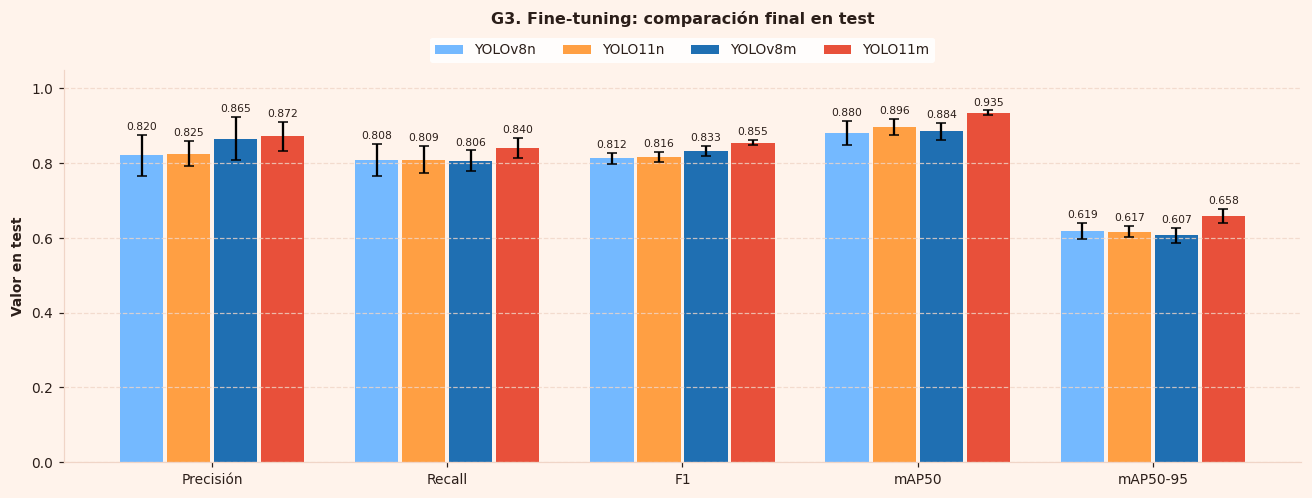

In [24]:
# G3. Comparación final en test (fine-tuning)
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(METRICAS))
ancho = 0.2
for i, tipo in enumerate(ORDEN):
    g = ft[ft['Modelo'] == tipo][METRICAS]
    barras = ax.bar(x + (i - (len(ORDEN) - 1) / 2) * ancho, g.mean(), ancho * 0.92,
                    yerr=g.std().fillna(0) if len(SEMILLAS) > 1 else None, capsize=3,
                    color=COLORES[tipo], label=tipo)
    ax.bar_label(barras, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, METRICAS)
ax.set(ylim=(0, 1.05), ylabel='Valor en test')
ax.set_title('G3. Fine-tuning: comparación final en test', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(ORDEN))
ax.grid(axis='x', visible=False)
plt.tight_layout()
guardar(fig, 'G3_comparacion_final.png')

### G4. *Learning rate* por época
**Qué muestra:** el *learning rate* de los pesos (`lr/pg0` en `results.csv`) al final de cada época, en escala logarítmica. La línea punteada vertical marca el paso de la Fase 1 a la Fase 2.

**Cómo leerla:**
- **Épocas 1–3 (*warmup*):** el LR sube desde casi 0 hasta `lr0`. Como se anota al final de cada época, se ve subir en tres escalones.
- **Resto de la Fase 1:** baja en línea recta (decaimiento lineal) hasta ≈ 11 % de `lr0`.
- **Fase 2:** vuelve a empezar en `lr0 / 10` (casi donde terminó la Fase 1) y baja hasta ≈ 0.3 % de `lr0`. Así, al descongelar el backbone, los pasos ya son pequeños y no se estropean los filtros de COCO.

**Qué buscar:** los modelos del mismo tamaño tienen el mismo `lr0`, así que sus líneas se superponen; solo se separan cuando el *early stopping* corta uno antes.
Los modelos *m* van siempre por debajo de los *n* (`lr0` = 3e-4 frente a 1e-3).

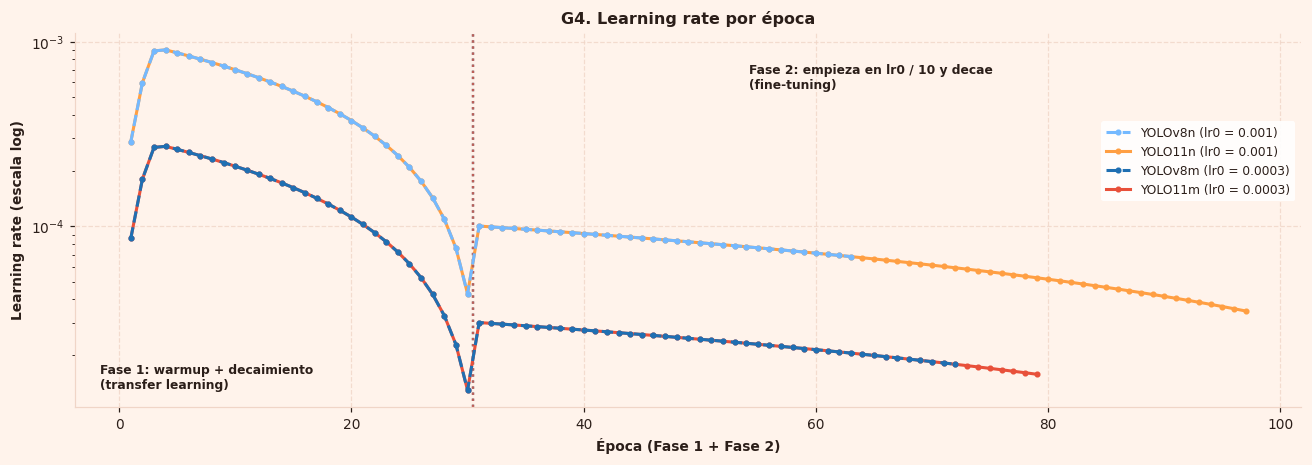

In [25]:
# G4. Learning rate por época (semilla 0)
fig, ax = plt.subplots(figsize=(12, 4.3))
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    ax.plot(h['epoca_total'], h['lr/pg0'], marker='.', lw=2, ls=LINEA[tipo], color=COLORES[tipo], zorder=CAPA[tipo],
            label=f"{tipo} (lr0 = {MODELOS[tipo]['lr0']:g})")
    ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLORES[tipo], ls=':', alpha=0.7)
ax.set_yscale('log')
ax.text(0.02, 0.05, 'Fase 1: warmup + decaimiento\n(transfer learning)', transform=ax.transAxes, fontsize=8, fontweight='bold')
ax.text(0.55, 0.85, 'Fase 2: empieza en lr0 / 10 y decae\n(fine-tuning)', transform=ax.transAxes, fontsize=8, fontweight='bold')
ax.set(title='G4. Learning rate por época', xlabel='Época (Fase 1 + Fase 2)', ylabel='Learning rate (escala log)')
ax.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.0, 0.78))
plt.tight_layout()
guardar(fig, 'G4_learning_rate.png')

### G5. mAP en validación por época
**Qué muestra:** el mAP50-95 (izquierda) y el mAP50 (derecha) **en validación** después de cada época. La línea punteada vertical marca el inicio de la Fase 2.
El rombo ◆ marca la época del `best.pt` de la Fase 1 (modelo de transfer learning) y la estrella ★ la del `best.pt` de la Fase 2 (modelo de fine-tuning).

**Cómo leerla:**
- Si el mAP sube al empezar la Fase 2, descongelar el backbone sirvió.
- Si la curva ya es plana al final, el modelo convergió; si todavía subía en la última época, más épocas podrían mejorar el resultado.
- Si el entrenamiento terminó antes de 50 épocas, actuó el *early stopping* (`PACIENCIA` épocas sin mejorar).

**Qué buscar:** qué modelo aprende más rápido (llega antes a un mAP alto) y cuál llega más alto.

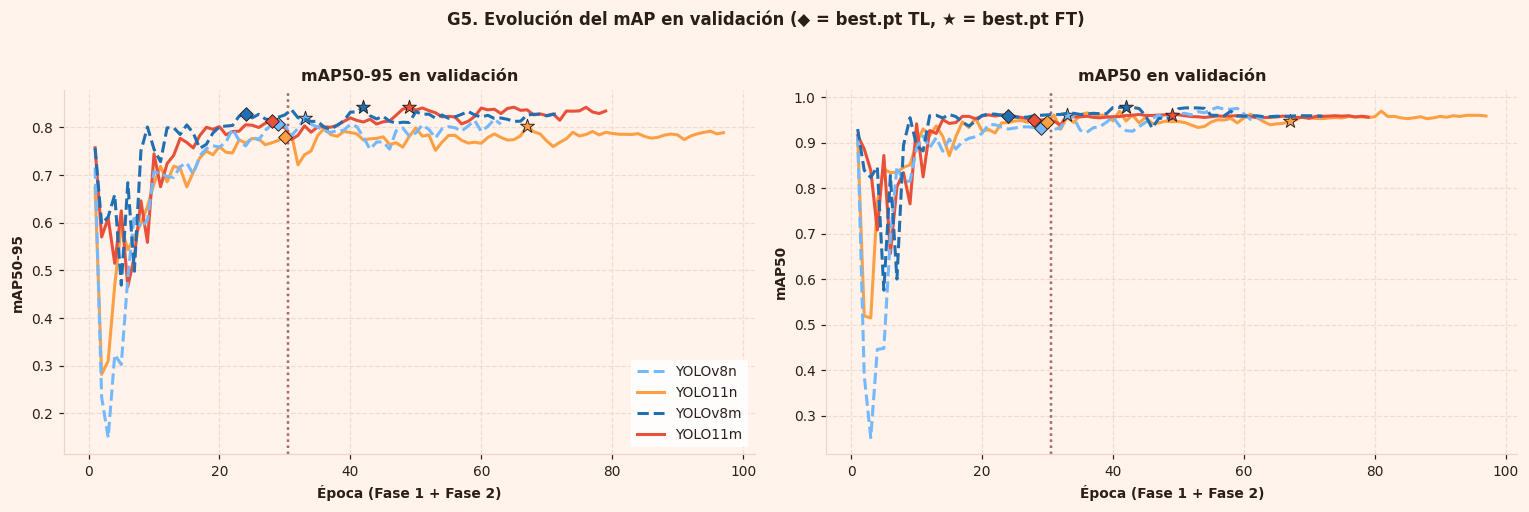

In [26]:
# G5. mAP en validación por época (semilla 0)
fig, (ax_map, ax_50) = plt.subplots(1, 2, figsize=(14, 4.5))
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    for ax, columna in ((ax_map, 'metrics/mAP50-95(B)'), (ax_50, 'metrics/mAP50(B)')):
        ax.plot(h['epoca_total'], h[columna], lw=2, ls=LINEA[tipo], color=COLORES[tipo], zorder=CAPA[tipo], label=tipo)
        ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLORES[tipo], ls=':', alpha=0.6)
        for fase, marcador in ((1, 'D'), (2, '*')):
            mejor = h.loc[h['fase'] == fase, 'metrics/mAP50-95(B)'].idxmax()   # best.pt = mayor mAP50-95 de la fase
            ax.scatter(h.loc[mejor, 'epoca_total'], h.loc[mejor, columna], marker=marcador, s=90 if marcador == '*' else 40,
                       color=COLORES[tipo], edgecolor=COLOR_TEXTO, linewidth=0.6, zorder=3)
ax_map.set(title='mAP50-95 en validación', xlabel='Época (Fase 1 + Fase 2)', ylabel='mAP50-95')
ax_50.set(title='mAP50 en validación', xlabel='Época (Fase 1 + Fase 2)', ylabel='mAP50')
ax_map.legend()
fig.suptitle('G5. Evolución del mAP en validación (◆ = best.pt TL, ★ = best.pt FT)', y=1.02)
plt.tight_layout()
guardar(fig, 'G5_map_por_epoca.png')

### G6. Pérdidas de entrenamiento y validación
**Qué muestra:** las tres pérdidas (filas: `box_loss`, `cls_loss`, `dfl_loss`) de cada modelo (columnas), en **train** (línea continua) y **validación** (discontinua), época a época.
Es la versión real de la gráfica "train vs val" de v1. La línea punteada vertical marca el inicio de la Fase 2.

**Cómo leerla:** ambas curvas deberían bajar. Con aumento de datos, train puede quedar **por encima** de validación: las imágenes de train
(mosaicos, cambios de color) son más difíciles que las de validación, que no se modifican.

**Qué buscar:**
- **Sobreajuste:** la pérdida de train sigue bajando mientras la de validación sube.
- Un escalón hacia abajo al empezar la Fase 2: al descongelar el backbone la red puede ajustarse mejor.
- Una caída brusca de train en las últimas 10 épocas: se apaga el mosaico (`close_mosaic`) y las imágenes de train se vuelven "normales".

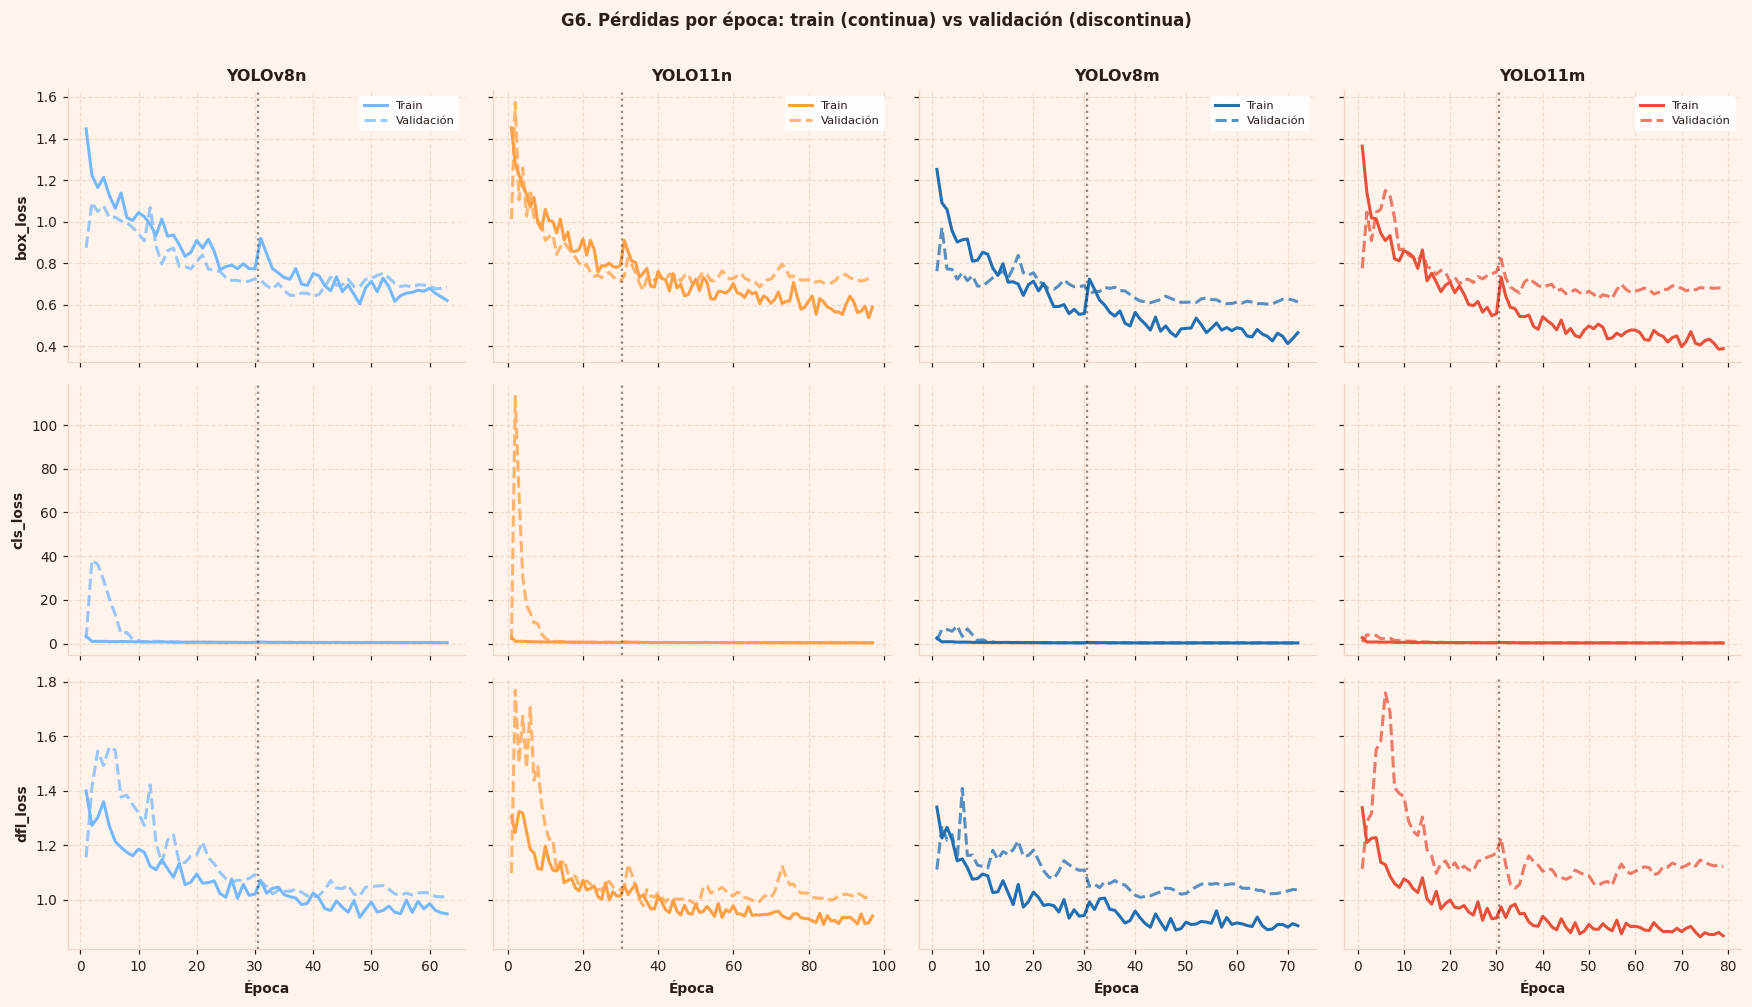

In [27]:
# G6. Pérdidas de train y validación por época (semilla 0)
PERDIDAS = ['box_loss', 'cls_loss', 'dfl_loss']
fig, ejes = plt.subplots(len(PERDIDAS), len(ORDEN), figsize=(16, 9), sharex='col', sharey='row')
for j, tipo in enumerate(ORDEN):
    h = HISTORIALES[tipo]
    for i, perdida in enumerate(PERDIDAS):
        ax = ejes[i, j]
        ax.plot(h['epoca_total'], h[f'train/{perdida}'], color=COLORES[tipo], lw=2, label='Train')
        ax.plot(h['epoca_total'], h[f'val/{perdida}'], color=COLORES[tipo], lw=2, ls='--', alpha=0.75, label='Validación')
        ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLOR_TEXTO, ls=':', alpha=0.5)
        if i == 0:
            ax.set_title(tipo)
            ax.legend(fontsize=7.5)
        if j == 0:
            ax.set_ylabel(perdida)
        if i == len(PERDIDAS) - 1:
            ax.set_xlabel('Época')
fig.suptitle('G6. Pérdidas por época: train (continua) vs validación (discontinua)', y=1.01)
plt.tight_layout()
guardar(fig, 'G6_perdidas_train_val.png')

### G7. Pérdidas finales de validación
**Qué muestra:** las pérdidas de **validación** de cada modelo fine-tuned en la época de su `best.pt` (estilo de la gráfica de pérdidas de v1).

**Cómo leerla:** más bajo es mejor. Se comparan modelos **dentro** de cada tipo de pérdida; las tres pérdidas tienen escalas distintas y no se comparan entre sí.

**Qué buscar:** `box_loss` baja ↔ cajas mejor ubicadas (se refleja en el mAP50-95); `cls_loss` baja ↔ distingue mejor naranja de fondo (precisión y recall);
`dfl_loss` baja ↔ bordes más precisos.

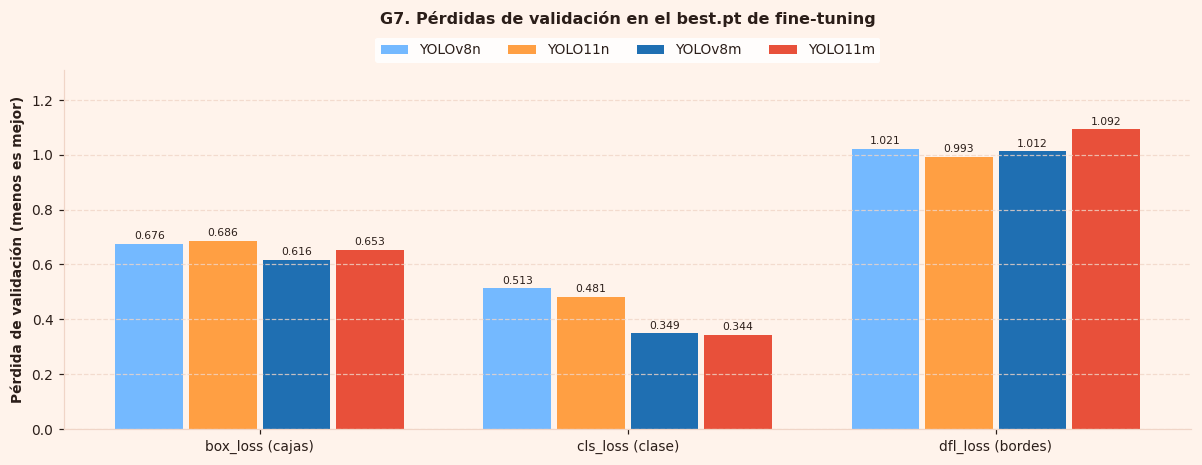

In [28]:
# G7. Pérdidas de validación en la época del best.pt de fine-tuning (semilla 0)
finales = {}
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    mejor = h.loc[h['fase'] == 2, 'metrics/mAP50-95(B)'].idxmax()
    finales[tipo] = [h.loc[mejor, f'val/{p}'] for p in PERDIDAS]

fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(len(PERDIDAS))
ancho = 0.2
for i, tipo in enumerate(ORDEN):
    barras = ax.bar(x + (i - (len(ORDEN) - 1) / 2) * ancho, finales[tipo], ancho * 0.92, color=COLORES[tipo], label=tipo)
    ax.bar_label(barras, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, ['box_loss (cajas)', 'cls_loss (clase)', 'dfl_loss (bordes)'])
ax.set(ylabel='Pérdida de validación (menos es mejor)', ylim=(0, max(max(v) for v in finales.values()) * 1.2))
ax.set_title('G7. Pérdidas de validación en el best.pt de fine-tuning', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(ORDEN))
ax.grid(axis='x', visible=False)
plt.tight_layout()
guardar(fig, 'G7_perdidas_finales.png')

### G8. Matrices de confusión
**Qué muestra:** la matriz de confusión de detección (sección 5.7) de cada modelo (columnas) en cada etapa (filas), contando cajas en test con el umbral de confianza de validación.
En v1 esta gráfica se dibujaba a partir de la precisión y el recall; aquí se **cuentan** las cajas de verdad.

**Cómo leerla:** fila *Real: naranja* = TP (encontradas) y FN (perdidas); fila *Real: fondo* = FP (falsas alarmas).
El color de cada casilla es su cantidad dividida entre el número de naranjas reales. En el título están la precisión TP / (TP + FP) y el recall TP / (TP + FN).

**Qué buscar:** en la etapa Pura suele haber muchos FN (COCO no reconoce naranjas pequeñas, verdes o tapadas por hojas).
¿El entrenamiento reduce sobre todo los FN (más recall) o los FP (más precisión)? ¿Qué modelo deja menos naranjas sin detectar?

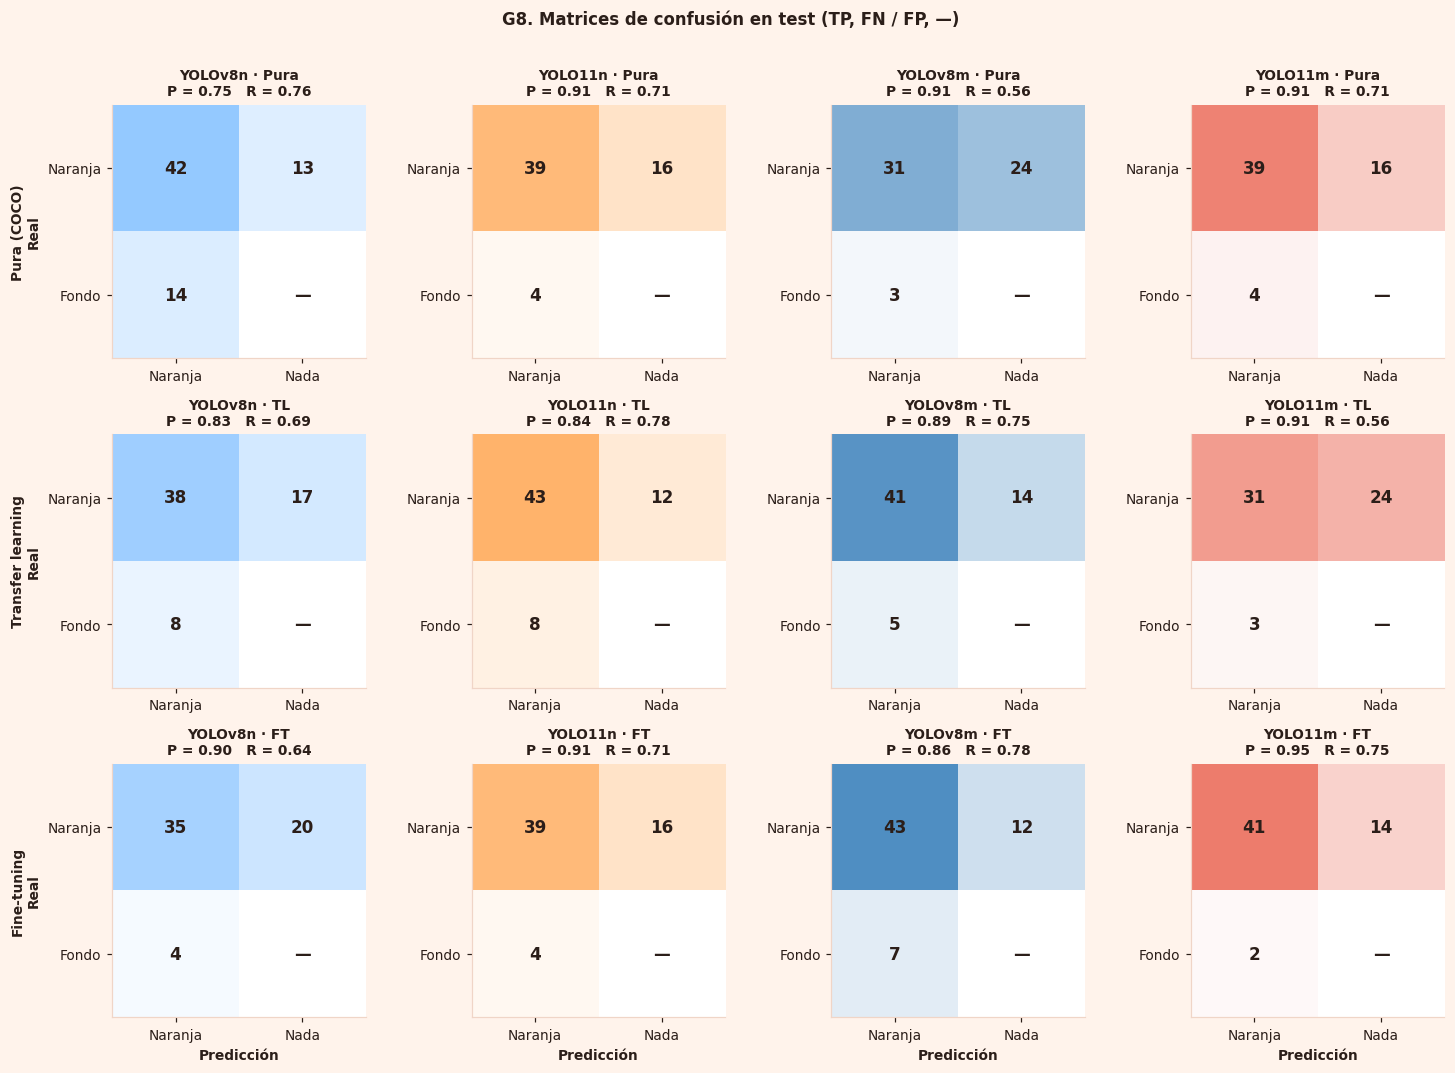

In [29]:
# G8. Matrices de confusión: filas = etapas, columnas = modelos
fig, ejes = plt.subplots(len(ETAPAS), len(ORDEN), figsize=(3.4 * len(ORDEN), 3.2 * len(ETAPAS)))
for i, etapa in enumerate(ETAPAS):
    for j, tipo in enumerate(ORDEN):
        ax = ejes[i, j]
        f = CONFUSION[(CONFUSION['Modelo'] == tipo) & (CONFUSION['Etapa'] == etapa)].iloc[0]
        reales = max(f['TP'] + f['FN'], 1)
        cuentas = np.array([[f['TP'], f['FN']], [f['FP'], 0]])
        mapa = LinearSegmentedColormap.from_list('', ['#FFFFFF', COLORES[tipo]])
        ax.imshow(cuentas / reales, cmap=mapa, vmin=0, vmax=1)
        for (fila, col), valor in np.ndenumerate(cuentas):
            texto = '—' if (fila, col) == (1, 1) else f'{int(valor)}'
            ax.text(col, fila, texto, ha='center', va='center', fontsize=11, fontweight='bold')
        ax.set_xticks([0, 1], ['Naranja', 'Nada'])
        ax.set_yticks([0, 1], ['Naranja', 'Fondo'])
        ax.grid(False)
        ax.set_title(f"{tipo} · {ETAPA_CORTA[etapa]}\nP = {f['Precisión']:.2f}   R = {f['Recall']:.2f}", fontsize=9)
        if i == len(ETAPAS) - 1:
            ax.set_xlabel('Predicción')
        if j == 0:
            ax.set_ylabel(f'{etapa}\nReal')
fig.suptitle('G8. Matrices de confusión en test (TP, FN / FP, —)', y=1.01)
plt.tight_layout()
guardar(fig, 'G8_matrices_confusion.png')

### G9. Curvas precisión–recall y F1–confianza (fine-tuning)
**Qué muestra:** a la izquierda, la curva **precisión–recall** (IoU 0.5) de cada modelo fine-tuned en test; su área es el AP50, que con una sola clase es el mAP50 (en la leyenda).
A la derecha, el **F1 según el umbral de confianza**; el punto marca el umbral elegido en validación.

**Cómo leerla:**
- PR: cuanto más arriba y a la derecha, mejor (alta precisión aun con recall alto). La curva cae al final: para encontrar las últimas naranjas
  (las difíciles) hay que aceptar detecciones poco seguras y aparecen falsas alarmas.
- F1: con un umbral muy bajo hay muchos FP; con uno muy alto, muchos FN. El máximo es el mejor equilibrio. Una meseta ancha significa que el modelo es poco sensible a la elección del umbral.

**Qué buscar:** el recall máximo al que llega cada curva (naranjas que el modelo nunca encuentra) y si el punto de validación cae cerca del máximo de F1 en test
(si es así, el umbral elegido en validación generaliza bien).

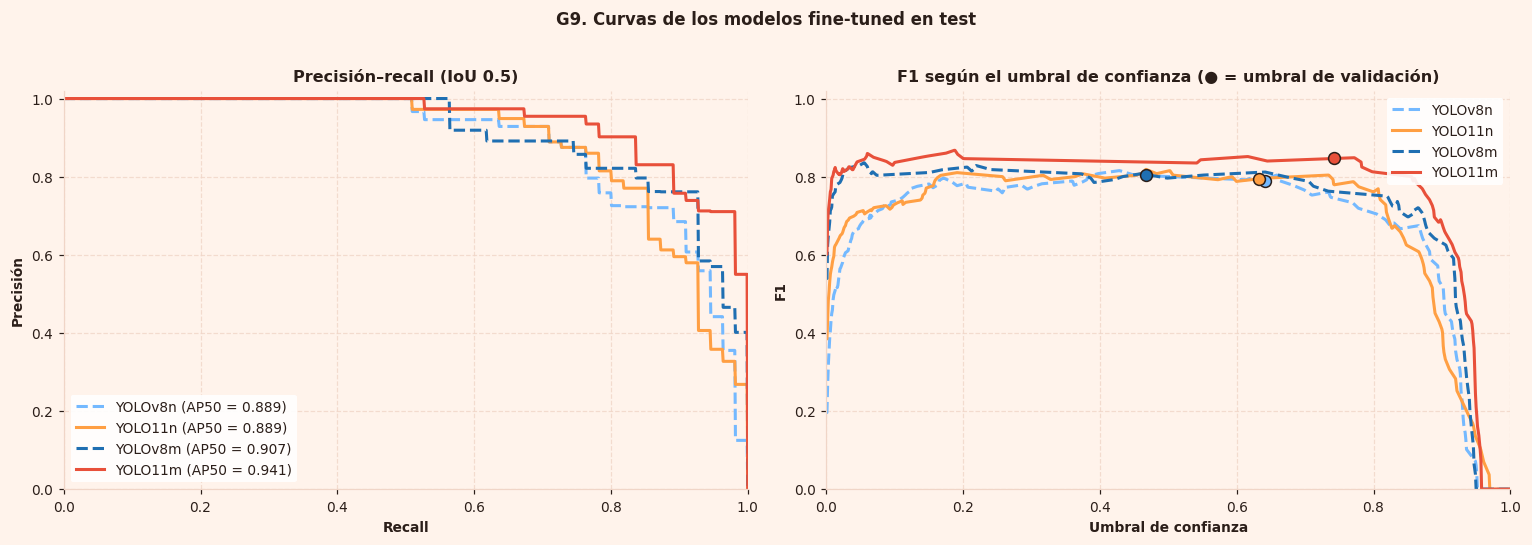

In [30]:
# G9. Curvas PR y F1-confianza en test (fine-tuning, mejor semilla)
fig, (ax_pr, ax_f1) = plt.subplots(1, 2, figsize=(14, 4.8))
for tipo in ORDEN:
    curvas = CURVAS[(tipo, 'Fine-tuning', semilla_de(tipo, 'Fine-tuning'))]
    fila = fila_de(tipo, 'Fine-tuning')
    ax_pr.plot(curvas['eje'], curvas['pr'], lw=2, ls=LINEA[tipo], color=COLORES[tipo], label=f"{tipo} (AP50 = {fila['mAP50']:.3f})")
    ax_f1.plot(curvas['eje'], curvas['f1'], lw=2, ls=LINEA[tipo], color=COLORES[tipo], label=tipo)
    umbral = fila['Umbral conf. (val)']
    ax_f1.scatter(umbral, np.interp(umbral, curvas['eje'], curvas['f1']), s=60, color=COLORES[tipo], edgecolor=COLOR_TEXTO, zorder=3)
ax_pr.set(title='Precisión–recall (IoU 0.5)', xlabel='Recall', ylabel='Precisión', xlim=(0, 1), ylim=(0, 1.02))
ax_f1.set(title='F1 según el umbral de confianza (● = umbral de validación)', xlabel='Umbral de confianza', ylabel='F1', xlim=(0, 1), ylim=(0, 1.02))
ax_pr.legend(loc='lower left')
ax_f1.legend(loc='upper right')
fig.suptitle('G9. Curvas de los modelos fine-tuned en test', y=1.02)
plt.tight_layout()
guardar(fig, 'G9_curvas_pr_f1.png')

### G10. Curvas precisión–recall por etapa
**Qué muestra:** para cada modelo, la curva precisión–recall en test de sus tres etapas (pálida = Pura, media = TL, llena = FT). El área bajo cada curva es su AP50.

**Cómo leerla:** el área que se gana entre dos curvas es la mejora de esa etapa. Si la curva de la etapa Pura se corta muy a la izquierda,
el modelo de COCO encuentra pocas naranjas aunque se le permita usar detecciones de muy baja confianza.

**Qué buscar:** si el transfer learning ya acerca la curva a la del fine-tuning (el backbone de COCO bastaba) o si la mejora grande llega al descongelar el backbone.

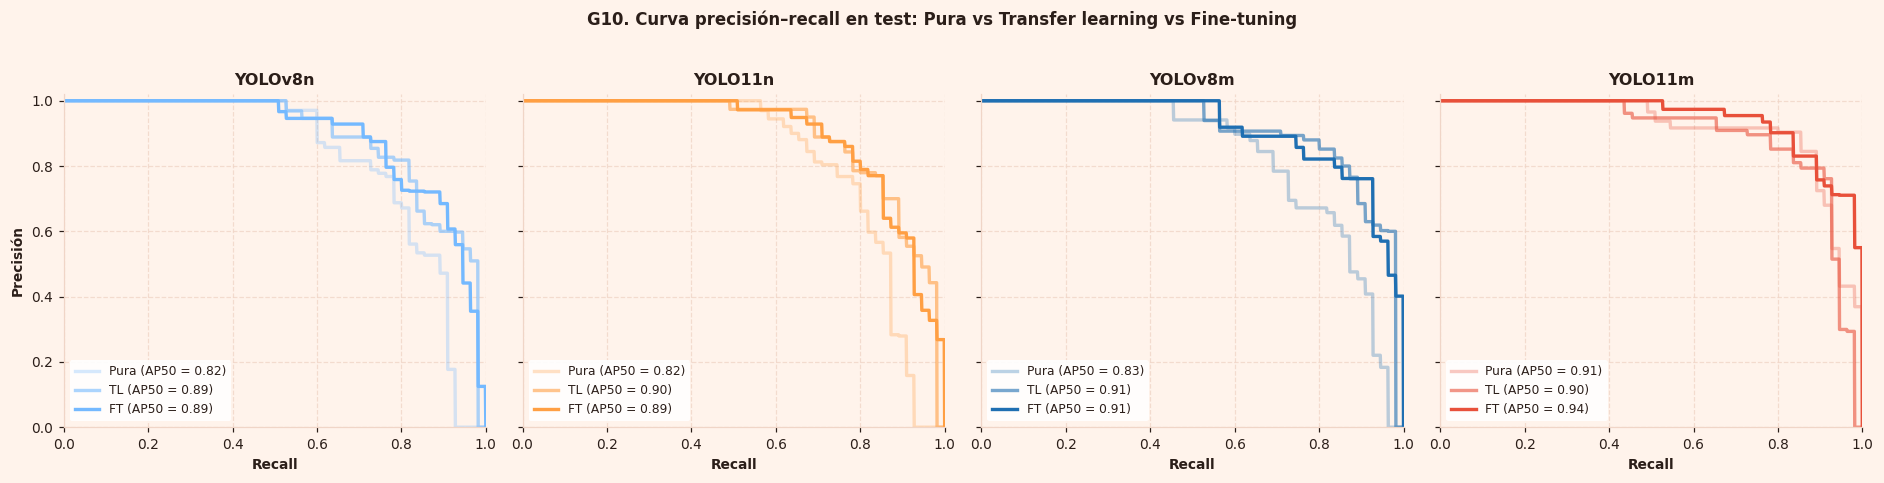

In [31]:
# G10. Curvas PR de las tres etapas de cada modelo
fig, ejes = plt.subplots(1, len(ORDEN), figsize=(4.3 * len(ORDEN), 4.2), sharey=True)
for ax, tipo in zip(ejes, ORDEN):
    for etapa in ETAPAS:
        curvas = CURVAS[(tipo, etapa, semilla_de(tipo, etapa))]
        ax.plot(curvas['eje'], curvas['pr'], lw=2.2, color=COLORES[tipo], alpha=ALFA_ETAPA[etapa],
                label=f"{ETAPA_CORTA[etapa]} (AP50 = {fila_de(tipo, etapa)['mAP50']:.2f})")
    ax.set(title=tipo, xlabel='Recall', xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc='lower left', fontsize=8)
ejes[0].set_ylabel('Precisión')
fig.suptitle('G10. Curva precisión–recall en test: Pura vs Transfer learning vs Fine-tuning', y=1.03)
plt.tight_layout()
guardar(fig, 'G10_curvas_pr_por_etapa.png')

### G11. Velocidad vs precisión
**Qué muestra:** cada modelo fine-tuned como un punto: latencia por imagen en el eje x y mAP50-95 en test en el eje y. El tamaño del punto es proporcional al número de parámetros.
La línea vertical marca 33 ms (≈ 30 FPS, tiempo real). Se usa la latencia de GPU si hay GPU; si no, la de CPU.

**Cómo leerla:** lo ideal es arriba a la izquierda (preciso y rápido). Un modelo está **dominado** si otro es a la vez más rápido y más preciso.
Los modelos no dominados, unidos por la línea gris, forman la **frontera de Pareto**: entre ellos no hay un "mejor" absoluto; depende de si importa más la velocidad o la precisión.

**Qué buscar:** cuánto mAP se gana por cada ms extra al pasar de *n* a *m*, y si YOLO11 domina a YOLOv8 del mismo tamaño.
Si el modelo se va a usar sin GPU, cambia `columna` a `'CPU (ms/img)'` y repite la gráfica.

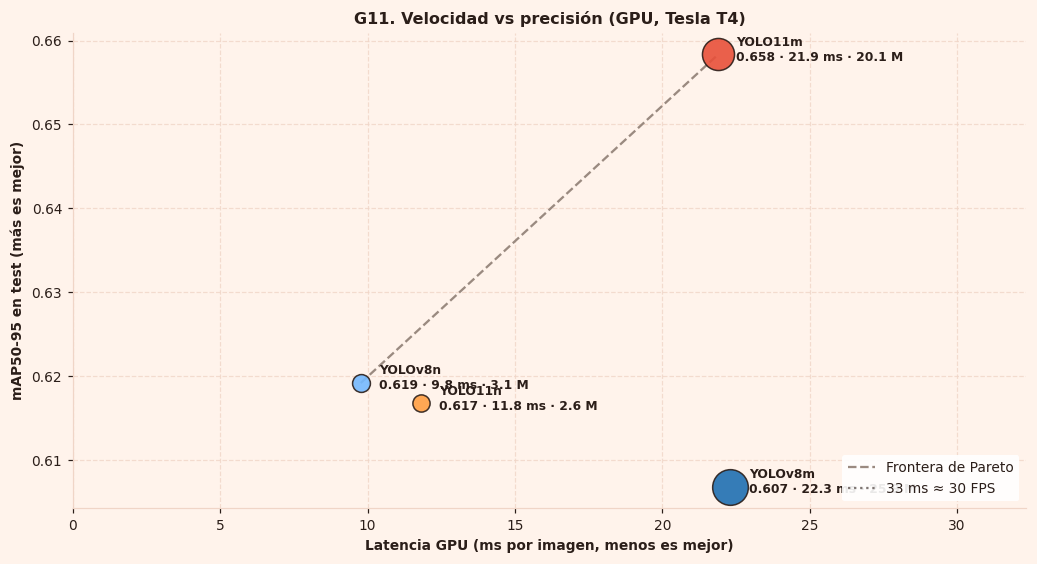

In [32]:
# G11. Velocidad vs precisión (fine-tuning)
columna = 'GPU (ms/img)' if 'GPU (ms/img)' in velocidad else 'CPU (ms/img)'
puntos = pd.DataFrame({'latencia': velocidad.loc[ORDEN, columna],
                       'map': medias.xs('Fine-tuning', level='Etapa').loc[ORDEN, 'mAP50-95'],
                       'params': velocidad.loc[ORDEN, 'Parámetros (M)']})
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for tipo, p in puntos.iterrows():
    ax.scatter(p['latencia'], p['map'], s=80 + 18 * p['params'], color=COLORES[tipo], edgecolor=COLOR_TEXTO, alpha=0.9, zorder=3)
    ax.annotate(f"{tipo}\n{p['map']:.3f} · {p['latencia']:.1f} ms · {p['params']:.1f} M", (p['latencia'], p['map']),
                xytext=(12, -4), textcoords='offset points', fontsize=8, fontweight='bold')
# Frontera de Pareto: recorriendo de más rápido a más lento, se queda cada modelo que mejora el mAP de todos los anteriores
frontera, mejor_map = [], -1
for tipo, p in puntos.sort_values('latencia').iterrows():
    if p['map'] > mejor_map:
        frontera.append(tipo)
        mejor_map = p['map']
ax.plot(puntos.loc[frontera, 'latencia'], puntos.loc[frontera, 'map'], color='#9a8a80', ls='--', lw=1.5, zorder=2, label='Frontera de Pareto')
ax.axvline(1000 / 30, color=COLOR_TEXTO, ls=':', alpha=0.6, label='33 ms ≈ 30 FPS')
ax.set_xlim(0, puntos['latencia'].max() * 1.45)
ax.set(title=f"G11. Velocidad vs precisión ({columna.split()[0]}, {velocidad['GPU usada'].iloc[0]})",
       xlabel=f'Latencia {columna.split()[0]} (ms por imagen, menos es mejor)', ylabel='mAP50-95 en test (más es mejor)')
ax.legend(loc='lower right')
plt.tight_layout()
guardar(fig, 'G11_velocidad_vs_precision.png')

### G12. Generalización entre datasets
**Qué muestra:** un panel por modelo. Cada celda es el mAP50-95 en test según **con qué se entrenó** el modelo (filas: nada / COCO, Mendeley, DeepFruits)
y **dónde se evalúa** (columnas: test de Mendeley, test de DeepFruits). Las celdas con borde oscuro son "en su dominio"; "—" = no disponible (falta v4 o la descarga).

**Cómo leerla:** cada columna de arriba abajo muestra cuánto mejora un mismo test según el entrenamiento.
Dentro de una fila, la diferencia entre la celda con borde y la otra es lo que se pierde al cambiar de dataset.

**Qué buscar:**
- **Mendeley → DeepFruits** frente a **Pura → DeepFruits**: si es mayor, lo aprendido con 1050 fotos de un huerto sirve en otro, sin reentrenar.
- **DeepFruits → Mendeley** frente a **Pura → Mendeley**: si es menor, con 52 fotos el modelo se especializó tanto que olvidó parte de lo que sabía.
- Qué dataset es "más difícil": compara las dos celdas de la diagonal.
- La columna de DeepFruits se mide con 7 fotos: diferencias pequeñas ahí no son fiables.

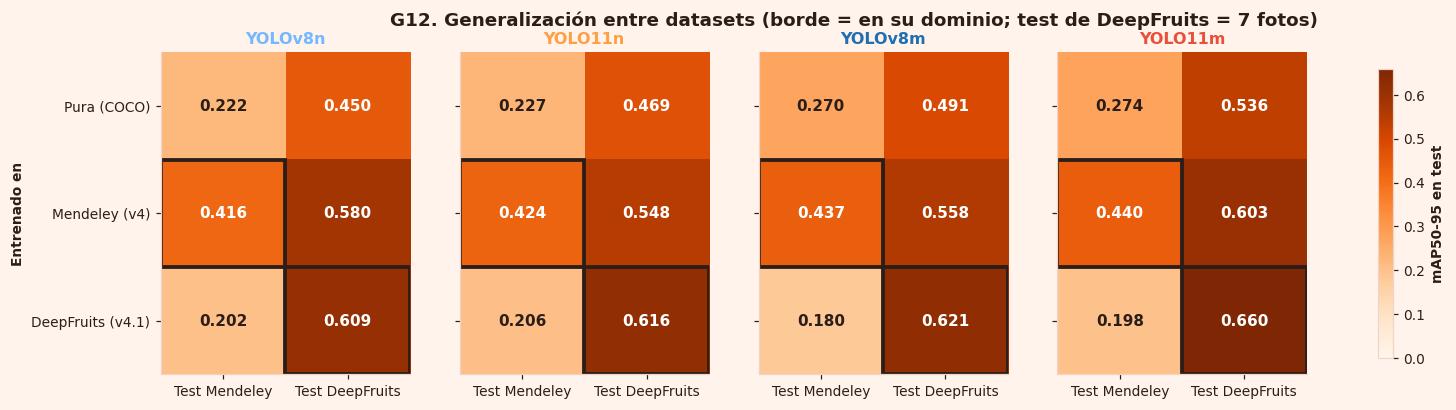

In [33]:
# G12. Generalización entre datasets: mAP50-95 en test (filas = entrenado en, columnas = test)
fig, ejes = plt.subplots(1, len(ORDEN), figsize=(4.2 * len(ORDEN), 3.8), sharey=True)
maximo = np.nanmax(tabla_generalizacion.to_numpy(dtype=float))
en_su_dominio = {('Mendeley (v4)', 'Mendeley'), ('DeepFruits (v4.1)', 'DeepFruits')}
for ax, tipo in zip(ejes, ORDEN):
    matriz = tabla_generalizacion.loc[tipo].loc[ORIGENES, TESTS].to_numpy(dtype=float)
    imagen = ax.imshow(matriz, cmap='Oranges', vmin=0, vmax=maximo, aspect='auto')
    for (i, j), valor in np.ndenumerate(matriz):
        texto = '—' if np.isnan(valor) else f'{valor:.3f}'
        ax.text(j, i, texto, ha='center', va='center', fontsize=10, fontweight='bold',
                color='white' if not np.isnan(valor) and valor > 0.6 * maximo else COLOR_TEXTO)
        if (ORIGENES[i], TESTS[j]) in en_su_dominio:
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=COLOR_TEXTO, lw=2.5))
    ax.set_xticks(range(len(TESTS)), [f'Test {t}' for t in TESTS])
    ax.set_yticks(range(len(ORIGENES)), ORIGENES)
    ax.set_title(tipo, color=COLORES[tipo])
    ax.grid(False)
ejes[0].set_ylabel('Entrenado en')
fig.colorbar(imagen, ax=ejes, label='mAP50-95 en test', shrink=0.9)
fig.suptitle('G12. Generalización entre datasets (borde = en su dominio; test de DeepFruits = 7 fotos)', fontsize=12)
guardar(fig, 'G12_generalizacion_entre_datasets.png')

### G13. Estructura de los modelos y parámetros de entrenamiento
**Qué muestra:** un diagrama (estilo v1) con los cuatro modelos y sus datos **medidos** en la sección 5.9: bloques, capas del backbone, parámetros, GFLOPs y tamaño del archivo.
En v1 estos números se escribían a mano; aquí salen de los modelos entrenados. Abajo, los hiperparámetros reales del entrenamiento.

**Cómo leerla:** de arriba abajo es el recorrido de una imagen: entra una foto de 640 × 640, cada modelo la procesa y sale una lista de cajas con confianza.

**Qué buscar:** relaciona el tamaño con la precisión de G3: el modelo *m* tiene ≈ 8 veces más parámetros que el *n*, pero no es 8 veces mejor (rendimientos decrecientes).

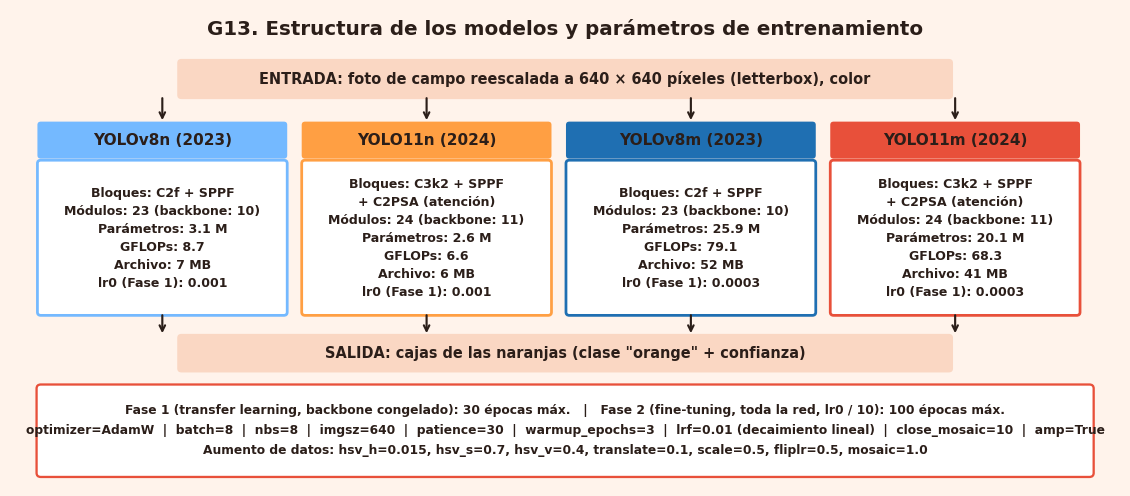

In [34]:
# G13. Diagrama de los modelos con datos medidos
DESCRIPCION = {'YOLOv8': ('2023', 'C2f + SPPF'), 'YOLO11': ('2024', 'C3k2 + SPPF\n+ C2PSA (atención)')}
fig, ax = plt.subplots(figsize=(13, 5.6))
ax.set_xlim(0, 13)
ax.set_ylim(-0.3, 5.6)
ax.axis('off')
ax.text(6.5, 5.3, 'G13. Estructura de los modelos y parámetros de entrenamiento', ha='center', fontsize=13, fontweight='bold')
ax.add_patch(FancyBboxPatch((2.0, 4.55), 9.0, 0.4, boxstyle='round,pad=0.05', facecolor='#FAD7C3', edgecolor='none'))
ax.text(6.5, 4.75, f'ENTRADA: foto de campo reescalada a {IMGSZ} × {IMGSZ} píxeles (letterbox), color', ha='center', va='center', fontsize=9.5, fontweight='bold')
ancho_caja = 2.85
for k, tipo in enumerate(ORDEN):
    x0 = 0.35 + k * 3.1
    centro = x0 + ancho_caja / 2
    generacion, bloques = DESCRIPCION['YOLO11' if tipo.startswith('YOLO11') else 'YOLOv8']
    v = velocidad.loc[tipo]
    ax.annotate('', xy=(centro, 4.2), xytext=(centro, 4.55), arrowprops=dict(arrowstyle='->', color=COLOR_TEXTO, lw=1.4))
    ax.add_patch(FancyBboxPatch((x0, 3.8), ancho_caja, 0.38, boxstyle='round,pad=0.04', facecolor=COLORES[tipo], edgecolor='none'))
    ax.text(centro, 3.99, f'{tipo} ({generacion})', ha='center', va='center', fontsize=10, fontweight='bold')
    ax.add_patch(FancyBboxPatch((x0, 1.85), ancho_caja, 1.85, boxstyle='round,pad=0.04', facecolor='white', edgecolor=COLORES[tipo], lw=1.8))
    texto = (f'Bloques: {bloques}\n'
             f"Módulos: {int(v['Bloques'])} (backbone: {int(v['Backbone'])})\n"
             f"Parámetros: {v['Parámetros (M)']:.1f} M\n"
             f"GFLOPs: {v['GFLOPs']:.1f}\n"
             f"Archivo: {v['Archivo (MB)']:.0f} MB\n"
             f"lr0 (Fase 1): {MODELOS[tipo]['lr0']:g}")
    ax.text(centro, 2.775, texto, ha='center', va='center', fontsize=8.2, fontweight='bold', linespacing=1.5)
    ax.annotate('', xy=(centro, 1.55), xytext=(centro, 1.85), arrowprops=dict(arrowstyle='->', color=COLOR_TEXTO, lw=1.4))
ax.add_patch(FancyBboxPatch((2.0, 1.15), 9.0, 0.38, boxstyle='round,pad=0.05', facecolor='#FAD7C3', edgecolor='none'))
ax.text(6.5, 1.34, 'SALIDA: cajas de las naranjas (clase "orange" + confianza)', ha='center', va='center', fontsize=9.5, fontweight='bold')
ax.add_patch(FancyBboxPatch((0.35, -0.15), 12.3, 1.05, boxstyle='round,pad=0.05', facecolor='white', edgecolor=COLORES['YOLO11m'], lw=1.5))
ax.text(6.5, 0.38, f'Fase 1 (transfer learning, backbone congelado): {EPOCAS_FASE1} épocas máx.   |   '
        f'Fase 2 (fine-tuning, toda la red, lr0 / 10): {EPOCAS_FASE2} épocas máx.\n'
        f'optimizer={OPTIMIZADOR}  |  batch={BATCH}  |  nbs={NBS}  |  imgsz={IMGSZ}  |  patience={PACIENCIA}  |  warmup_epochs=3  |  '
        f'lrf=0.01 (decaimiento lineal)  |  close_mosaic=10  |  amp=True\n'
        'Aumento de datos: ' + ', '.join(f'{k}={v}' for k, v in AUMENTACION.items()),
        ha='center', va='center', fontsize=8, fontweight='bold', linespacing=1.7)
guardar(fig, 'G13_estructura_modelos.png')

### G14. Detecciones de los cuatro modelos
**Qué muestra:** tres imágenes de test con las naranjas reales (primera columna) y las detectadas por cada modelo fine-tuned con su umbral de validación.
El número entre paréntesis es la cantidad de cajas.

**Cómo leerla:** compara cada columna con la primera: cajas de más son FP, naranjas sin caja son FN.

**Qué buscar:** qué naranjas se pierden (pequeñas, tapadas, verdes, a contraluz) y si los modelos *m* las encuentran.

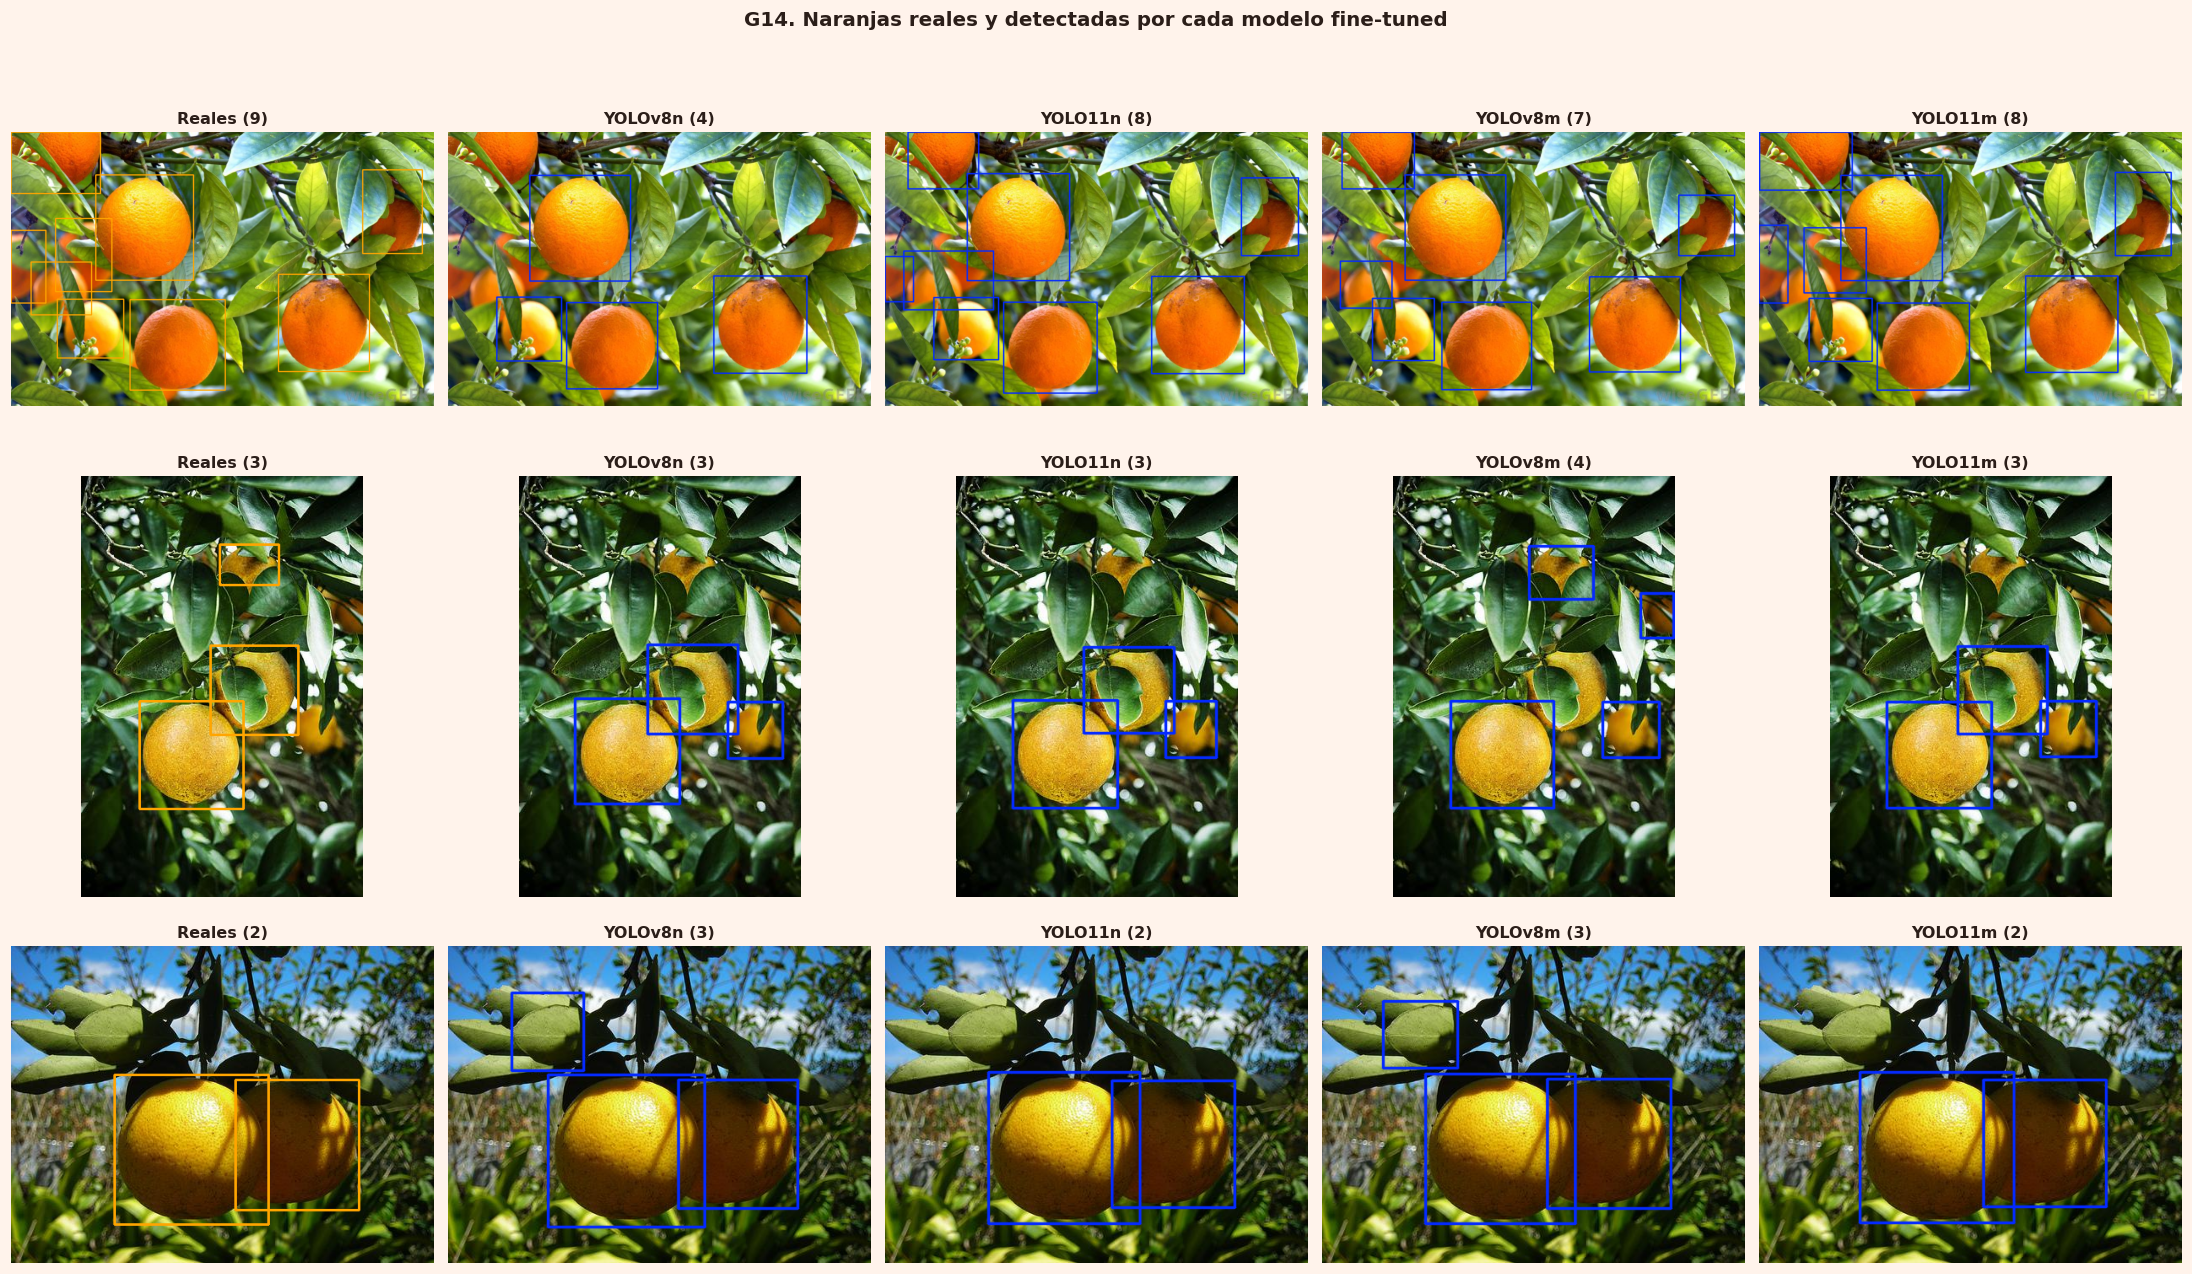

In [35]:
# G14. Comparación visual de los modelos fine-tuned sobre las mismas imágenes de test
modelos_finales = {tipo: cargar_modelo(pesos) for tipo, pesos in PESOS_MEJORES.items()}
muestra = list(test_tabla['archivo'].sample(frac=1, random_state=0).head(3))

fig, ejes = plt.subplots(len(muestra), len(MODELOS) + 1, figsize=(4 * (len(MODELOS) + 1), 4 * len(muestra)), squeeze=False)
for fila, archivo in enumerate(muestra):
    imagen = cv2.imread(str(ruta_imagen(archivo, 'test')))
    reales = imagen.copy()
    cajas = leer_cajas(archivo, 'test', imagen.shape[1], imagen.shape[0])
    for x1, y1, x2, y2 in cajas.astype(int):
        cv2.rectangle(reales, (x1, y1), (x2, y2), (0, 165, 255), 2)
    ejes[fila, 0].imshow(a_rgb(reales))
    ejes[fila, 0].set_title(f'Reales ({len(cajas)})')
    for col, (tipo, modelo) in enumerate(modelos_finales.items(), start=1):
        r = modelo.predict(imagen, conf=float(MEJOR.loc[tipo, 'Umbral conf. (val)']), imgsz=IMGSZ, verbose=False)[0]
        ejes[fila, col].imshow(a_rgb(r.plot(labels=False, conf=False)))
        ejes[fila, col].set_title(f'{tipo} ({len(r.boxes)})')
for ax in ejes.flat:
    ax.axis('off')
fig.suptitle('G14. Naranjas reales y detectadas por cada modelo fine-tuned', y=1.0, fontsize=13)
plt.tight_layout()
guardar(fig, 'G14_comparacion_visual.png')

### G15. Detecciones en las tres etapas
**Qué muestra:** una misma imagen de test con muchas naranjas: las reales (primera columna) y las detectadas por cada modelo (filas) en cada etapa (columnas).

**Cómo leerla:** de izquierda a derecha se ve el efecto de cada etapa sobre las mismas naranjas.

**Qué buscar:** la etapa Pura suele detectar solo las naranjas grandes y bien visibles; el transfer learning y el fine-tuning deberían recuperar las pequeñas y las tapadas.

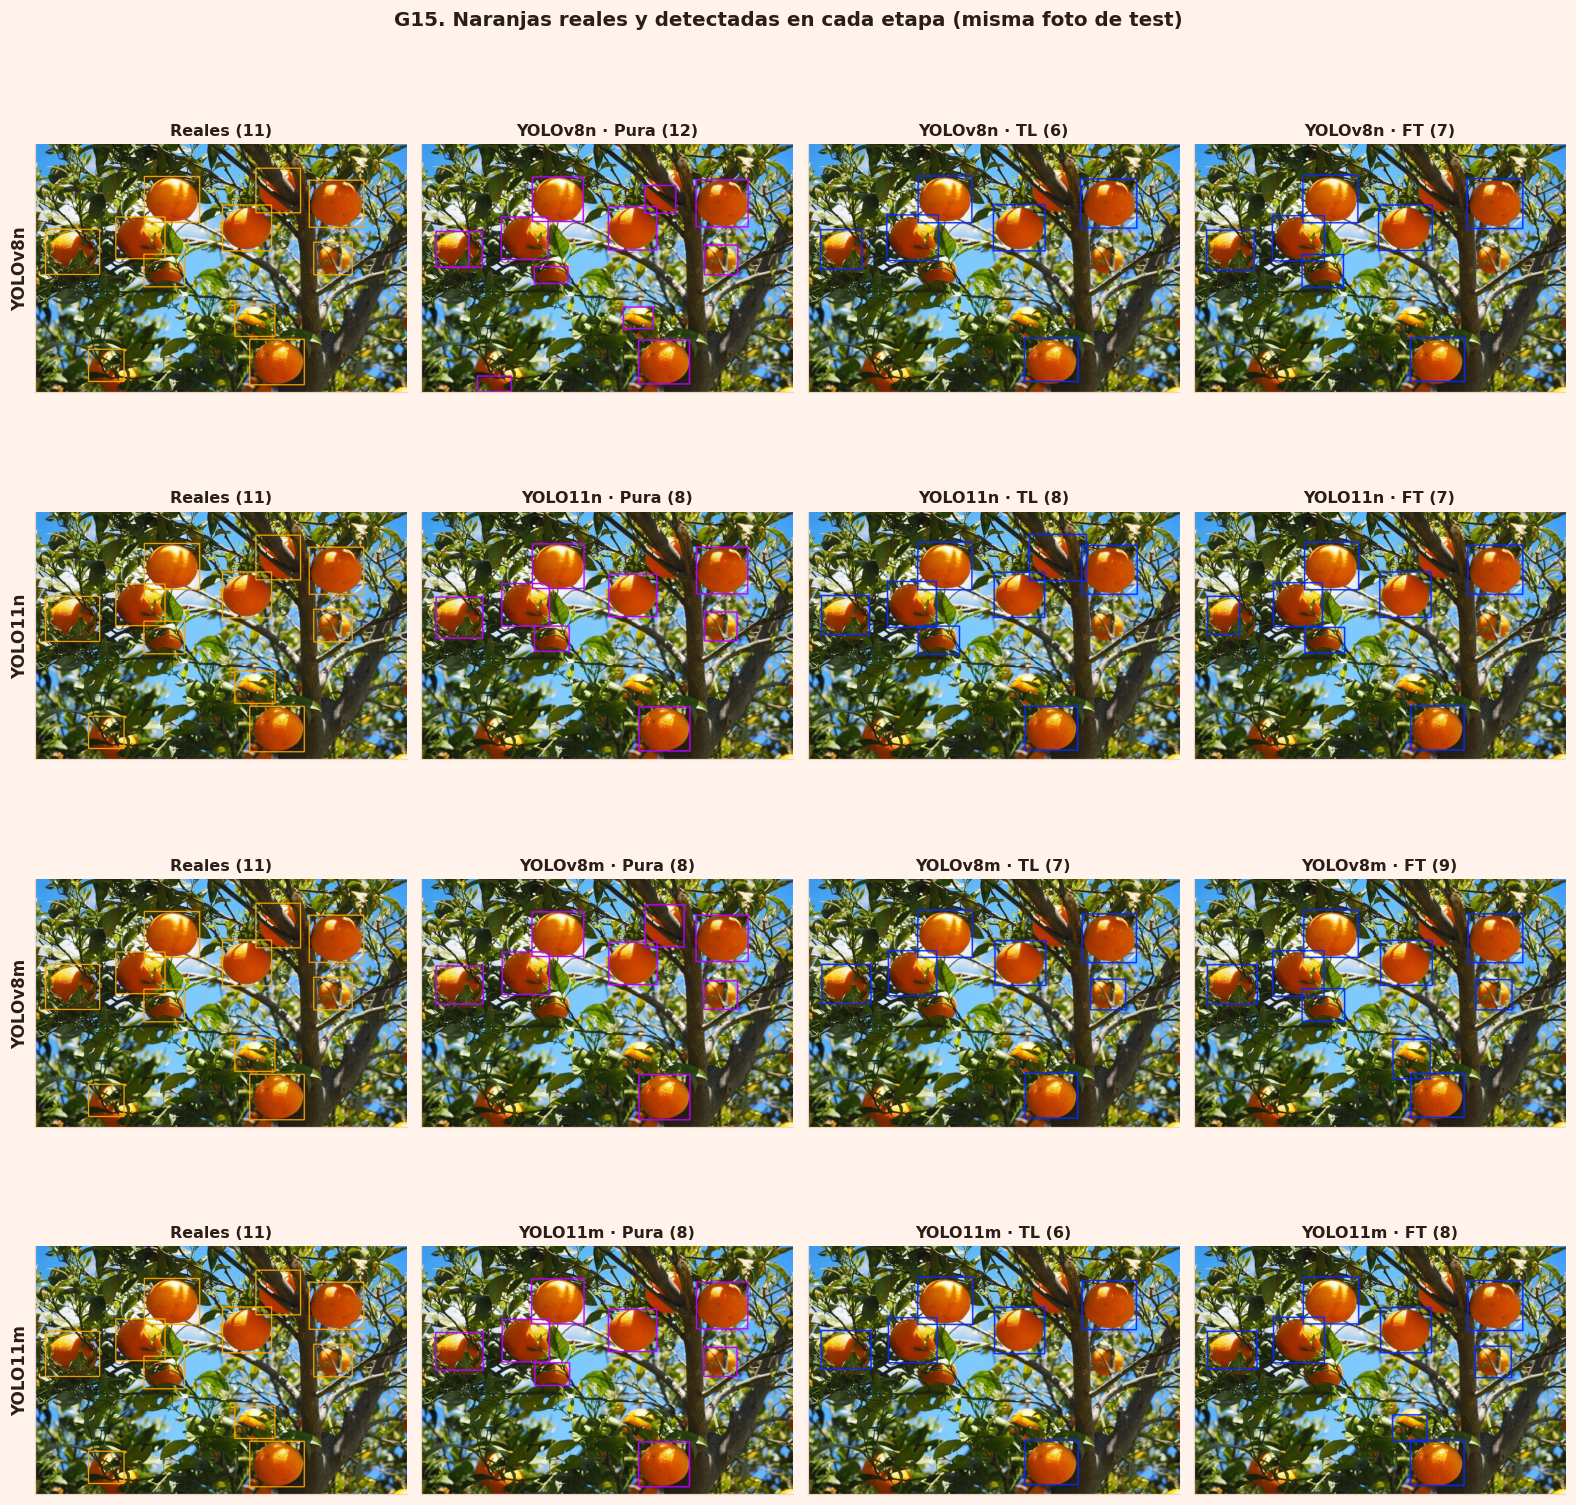

In [36]:
# G15. Una imagen de test: reales vs las tres etapas de cada modelo
conteo = np.array([len(leer_cajas(a, 'test')) for a in test_tabla['archivo']])
archivo = test_tabla['archivo'].iloc[int(np.argsort(conteo)[int(len(conteo) * 0.75)])]   # Percentil 75 de naranjas por imagen
imagen = cv2.imread(str(ruta_imagen(archivo, 'test')))
cajas = leer_cajas(archivo, 'test', imagen.shape[1], imagen.shape[0])
reales = imagen.copy()
for x1, y1, x2, y2 in cajas.astype(int):
    cv2.rectangle(reales, (x1, y1), (x2, y2), (0, 165, 255), 2)

fig, ejes = plt.subplots(len(ORDEN), len(ETAPAS) + 1, figsize=(3.6 * (len(ETAPAS) + 1), 3.6 * len(ORDEN)))
for i, tipo in enumerate(ORDEN):
    ejes[i, 0].imshow(a_rgb(reales))
    ejes[i, 0].set_title(f'Reales ({len(cajas)})')
    ejes[i, 0].set_ylabel(tipo, fontsize=11)
    for j, etapa in enumerate(ETAPAS, start=1):
        modelo = cargar_modelo(pesos_de(tipo, etapa, semilla_de(tipo, etapa)))
        clases = [ID_NARANJA_COCO] if etapa == 'Pura (COCO)' else None
        r = modelo.predict(imagen, conf=float(fila_de(tipo, etapa)['Umbral conf. (val)']), classes=clases, imgsz=IMGSZ, verbose=False)[0]
        ejes[i, j].imshow(a_rgb(r.plot(labels=False, conf=False)))
        ejes[i, j].set_title(f'{tipo} · {ETAPA_CORTA[etapa]} ({len(r.boxes)})')
        del modelo
for ax in ejes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle('G15. Naranjas reales y detectadas en cada etapa (misma foto de test)', y=1.0, fontsize=13)
plt.tight_layout()
guardar(fig, 'G15_deteccion_por_etapa.png')
liberar_memoria()

---
## 7. Conclusiones
La celda siguiente resume los resultados **calculados** en este notebook: si se vuelve a entrenar, los números cambian solos.
Después hay preguntas guía para redactar las conclusiones del informe o la presentación.

In [37]:
# 7.1 Resumen automático de los resultados
ft_medias = medias.xs('Fine-tuning', level='Etapa').loc[ORDEN]
col_vel = 'GPU (ms/img)' if 'GPU (ms/img)' in velocidad else 'CPU (ms/img)'
lineas = [f"Modelo final (mayor mAP50-95 en validación): {MEJOR['mAP50-95 val'].idxmax()}",
          f"Mayor mAP50-95 en test: {ft_medias['mAP50-95'].idxmax()} ({ft_medias['mAP50-95'].max():.3f})",
          f"Más rápido ({col_vel.split()[0]}): {velocidad[col_vel].idxmin()} ({velocidad[col_vel].min():.1f} ms/img, "
          f"{1000 / velocidad[col_vel].min():.0f} FPS)", '', 'Etapas (mAP50-95 en test):']
for tipo in ORDEN:
    pura, tl, ft_ = tabla_etapas.loc[tipo, ETAPAS]
    lineas.append(f'  {tipo}: Pura {pura:.3f} → TL {tl:.3f} ({tl - pura:+.3f}) → FT {ft_:.3f} ({ft_ - tl:+.3f})')
lineas += ['', 'Generación (mismo tamaño, fine-tuning):']
for tam in 'nm':
    v8, v11 = f'YOLOv8{tam}', f'YOLO11{tam}'
    lineas.append(f"  {v11} vs {v8}: mAP50-95 {ft_medias.loc[v11, 'mAP50-95'] - ft_medias.loc[v8, 'mAP50-95']:+.3f}, "
                  f"latencia {velocidad.loc[v11, col_vel]:.1f} vs {velocidad.loc[v8, col_vel]:.1f} ms, "
                  f"parámetros {velocidad.loc[v11, 'Parámetros (M)']:.1f} vs {velocidad.loc[v8, 'Parámetros (M)']:.1f} M")
lineas += ['', 'Tamaño (misma generación, fine-tuning):']
for gen in ('YOLOv8', 'YOLO11'):
    n, m = f'{gen}n', f'{gen}m'
    lineas.append(f"  {m} vs {n}: mAP50-95 {ft_medias.loc[m, 'mAP50-95'] - ft_medias.loc[n, 'mAP50-95']:+.3f}, "
                  f"{velocidad.loc[m, col_vel] / velocidad.loc[n, col_vel]:.1f}× más lento, "
                  f"{velocidad.loc[m, 'Parámetros (M)'] / velocidad.loc[n, 'Parámetros (M)']:.1f}× más parámetros")
if INFO_V4:
    lineas += ['', 'Las mismas etapas con Mendeley (v4, mAP50-95 en test de Mendeley):']
    for tipo in ORDEN:
        if tipo in INFO_V4['modelos']:
            pura, tl, ft_ = (INFO_V4['modelos'][tipo]['mAP50-95 test por etapa'][e] for e in ETAPAS)
            lineas.append(f'  {tipo}: Pura {pura:.3f} → TL {tl:.3f} ({tl - pura:+.3f}) → FT {ft_:.3f} ({ft_ - tl:+.3f})')
lineas += ['', 'Generalización entre datasets (mAP50-95 en test; nan = no disponible):']
for tipo in ORDEN:
    g = tabla_generalizacion.loc[tipo]
    lineas.append(f"  {tipo}: en DeepFruits, Mendeley {g.loc['Mendeley (v4)', 'DeepFruits']:.3f} vs Pura {g.loc['Pura (COCO)', 'DeepFruits']:.3f} "
                  f"vs propio {g.loc['DeepFruits (v4.1)', 'DeepFruits']:.3f} | en Mendeley, DeepFruits {g.loc['DeepFruits (v4.1)', 'Mendeley']:.3f} "
                  f"vs Pura {g.loc['Pura (COCO)', 'Mendeley']:.3f} vs propio {g.loc['Mendeley (v4)', 'Mendeley']:.3f}")
lineas += ['', f'Nota: el test tiene {len(test_tabla)} fotos; diferencias de ≈ 0.02–0.03 en mAP50-95 entre modelos pueden deberse al azar.']
if len(SEMILLAS) == 1:
    lineas.append('Con 1 semilla no se puede medir esa variación: usa el perfil "completo" para confirmarla.')
print('\n'.join(lineas))
(CARPETA_RESULTADOS / 'conclusiones.txt').write_text('\n'.join(lineas), encoding='utf-8')

Modelo final (mayor mAP50-95 en validación): YOLOv8m
Mayor mAP50-95 en test: YOLO11m (0.658)
Más rápido (GPU): YOLOv8n (9.8 ms/img, 102 FPS)

Etapas (mAP50-95 en test):
  YOLOv8n: Pura 0.450 → TL 0.605 (+0.155) → FT 0.619 (+0.014)
  YOLO11n: Pura 0.469 → TL 0.603 (+0.134) → FT 0.617 (+0.013)
  YOLOv8m: Pura 0.491 → TL 0.614 (+0.122) → FT 0.607 (-0.007)
  YOLO11m: Pura 0.536 → TL 0.635 (+0.100) → FT 0.658 (+0.023)

Generación (mismo tamaño, fine-tuning):
  YOLO11n vs YOLOv8n: mAP50-95 -0.002, latencia 11.8 vs 9.8 ms, parámetros 2.6 vs 3.1 M
  YOLO11m vs YOLOv8m: mAP50-95 +0.052, latencia 21.9 vs 22.3 ms, parámetros 20.1 vs 25.9 M

Tamaño (misma generación, fine-tuning):
  YOLOv8m vs YOLOv8n: mAP50-95 -0.012, 2.3× más lento, 8.2× más parámetros
  YOLO11m vs YOLO11n: mAP50-95 +0.042, 1.9× más lento, 7.7× más parámetros

Las mismas etapas con Mendeley (v4, mAP50-95 en test de Mendeley):
  YOLOv8n: Pura 0.222 → TL 0.379 (+0.157) → FT 0.416 (+0.037)
  YOLO11n: Pura 0.227 → TL 0.386 (+0.159) 

1854

### 7.2 Preguntas guía
1. **Etapas con pocos datos:** ¿cuánto mejora cada modelo de Pura a Transfer learning y de Transfer learning a Fine-tuning (G1, G2, G10)?
   Compáralo con v4 (resumen 7.1): ¿el fine-tuning aporta más o menos cuando solo hay 52 fotos?
2. **Generación:** con el mismo tamaño, ¿YOLO11 supera a YOLOv8 (G3)? ¿Es más rápido (G11)? ¿Se mantiene el resultado de v4?
3. **Tamaño:** con tan pocas fotos, ¿el modelo *m* sigue ganando al *n*, o sobreajusta (G6)? ¿Cuánto cuesta en latencia (G11)?
4. **Entrenamiento:** ¿la pérdida de validación sube mientras la de train baja (G6)? ¿En qué época se eligió el `best.pt` (G5)?
   Con varias semillas: ¿cuánto cambia el resultado solo por azar (desviación en la tabla 5.6)?
5. **Errores:** ¿los modelos fallan más por FN (naranjas perdidas) o por FP (falsas alarmas) (G8, G14)?
6. **Generalización (G12):** ¿el modelo de Mendeley funciona en DeepFruits sin reentrenar? ¿Y al revés?
   ¿Qué te dice esto sobre usar un modelo en un huerto distinto al de las fotos con que se entrenó?
7. **Fiabilidad:** con 7 fotos de test, ¿qué diferencias te parecen reales? ¿Cuántas fotos más etiquetarías para estar seguro?
8. **Elección:** ¿qué modelo usarías en la demo con GPU? ¿Y en un dispositivo sin GPU (latencia de CPU en la tabla 5.9)?

---
## 8. Guardar los modelos y elegir el modelo final
Se copian los mejores pesos fine-tuned de cada modelo a la carpeta `modelos/v4_1/` del proyecto, con nombres claros, y se escribe `modelos.json` con:
qué modelo es el final, el umbral de confianza de cada uno y sus métricas.

El **modelo final** es el de mayor **mAP50-95 en validación**. No se elige con test: si eligiéramos "el que mejor sale en test",
el número de test dejaría de ser una medida honesta de cómo funcionará con imágenes nuevas.
Si para tu caso importa más la velocidad (por ejemplo, una cámara en tiempo real sin GPU), mira también la tabla de la sección 5.9 y la gráfica G11.

In [38]:
# 8.1 Guardar
FINAL = MEJOR['mAP50-95 val'].idxmax()
info = {'final': FINAL, 'experimento': NOMBRE_EXPERIMENTO, 'dataset': f"{ROBOFLOW['proyecto']} v{ROBOFLOW['version']}",
        'perfil': PERFIL, 'imgsz': IMGSZ, 'modelos': {}}
for tipo, pesos in PESOS_MEJORES.items():
    archivo = f"orange_{tipo.lower().replace('-', '')}.pt"
    shutil.copy(pesos, CARPETA_MODELOS / archivo)
    info['modelos'][tipo] = {'archivo': archivo,
                             'umbral_conf': round(float(MEJOR.loc[tipo, 'Umbral conf. (val)']), 3),
                             'mAP50-95 val': round(float(MEJOR.loc[tipo, 'mAP50-95 val']), 4),
                             'mAP50-95 test': round(float(MEJOR.loc[tipo, 'mAP50-95']), 4),
                             'mAP50-95 test por etapa': {e: round(float(tabla_etapas.loc[tipo, e]), 4) for e in ETAPAS}}
(CARPETA_MODELOS / 'modelos.json').write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(info, indent=2, ensure_ascii=False))
print(f'\nModelo final: {FINAL}. Archivos en {CARPETA_MODELOS}')

{
  "final": "YOLOv8m",
  "experimento": "v4_1_deepfruits",
  "dataset": "deepfruits-orange v2",
  "perfil": "completo",
  "imgsz": 640,
  "modelos": {
    "YOLOv8n": {
      "archivo": "orange_yolov8n.pt",
      "umbral_conf": 0.642,
      "mAP50-95 val": 0.8208,
      "mAP50-95 test": 0.6087,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.4498,
        "Transfer learning": 0.6048,
        "Fine-tuning": 0.6192
      }
    },
    "YOLO11n": {
      "archivo": "orange_yolo11n.pt",
      "umbral_conf": 0.633,
      "mAP50-95 val": 0.8083,
      "mAP50-95 test": 0.6157,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.4693,
        "Transfer learning": 0.6035,
        "Fine-tuning": 0.6167
      }
    },
    "YOLOv8m": {
      "archivo": "orange_yolov8m.pt",
      "umbral_conf": 0.467,
      "mAP50-95 val": 0.8434,
      "mAP50-95 test": 0.6211,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.4915,
        "Transfer learning": 0.6136,
        "Fine-tun

---
## 9. Usar el modelo entrenado (sin volver a entrenar)
Los modelos quedan guardados en `modelos/v4_1/` dentro de la carpeta del proyecto. Para usarlos otro día **no hace falta entrenar de nuevo**:
1. Ejecuta las celdas de la **sección 1** (instalación, configuración, carpetas y funciones).
2. Ejecuta las celdas de esta sección.

También puedes usar los modelos fuera de este notebook con dos líneas:
```python
from ultralytics import YOLO
modelo = YOLO('modelos/v4_1/orange_yolo11m.pt')
modelo.predict('foto.jpg', conf=0.3, show=True)
```

In [39]:
# 9.1 Cargar los modelos guardados
info_modelos = json.loads((CARPETA_MODELOS / 'modelos.json').read_text(encoding='utf-8'))
MODELO_FINAL = info_modelos['final']
modelos_listos = {tipo: cargar_modelo(CARPETA_MODELOS / d['archivo']) for tipo, d in info_modelos['modelos'].items()}
UMBRALES = {tipo: d['umbral_conf'] for tipo, d in info_modelos['modelos'].items()}
print('Modelos cargados:', list(modelos_listos), '| final:', MODELO_FINAL)


def mostrar_detecciones(imagen, comparar=True):
    """Dibuja las naranjas detectadas. imagen = ruta o imagen de OpenCV. comparar=True usa los cuatro modelos."""
    if not isinstance(imagen, np.ndarray):
        ruta = imagen
        imagen = cv2.imread(str(ruta))
        if imagen is None:
            print(f'No se pudo leer {ruta}. Usa una imagen .jpg o .png.')
            return
    tipos = list(modelos_listos) if comparar else [MODELO_FINAL]
    fig, ejes = plt.subplots(1, len(tipos), figsize=(5 * len(tipos), 5), squeeze=False)
    for ax, tipo in zip(ejes[0], tipos):
        r = modelos_listos[tipo].predict(imagen, conf=UMBRALES[tipo], imgsz=IMGSZ, verbose=False)[0]
        ax.imshow(a_rgb(r.plot(labels=False)))
        ax.set_title(f'{tipo}: {len(r.boxes)} naranjas (conf ≥ {UMBRALES[tipo]:.2f})')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Modelos cargados: ['YOLOv8n', 'YOLO11n', 'YOLOv8m', 'YOLO11m'] | final: YOLOv8m


### 9.2 Probar con una imagen subida (sin cámara)
- **En Colab**: al ejecutar la celda aparece un botón *Elegir archivos*; puedes subir una o varias fotos.
- **En tu computadora**: escribe la ruta de tus fotos en `IMAGENES_LOCALES`.

Pon `COMPARAR_TODOS = False` para ver solo el modelo final.

Saving OrangeBloss_wb.jpg to OrangeBloss_wb.jpg


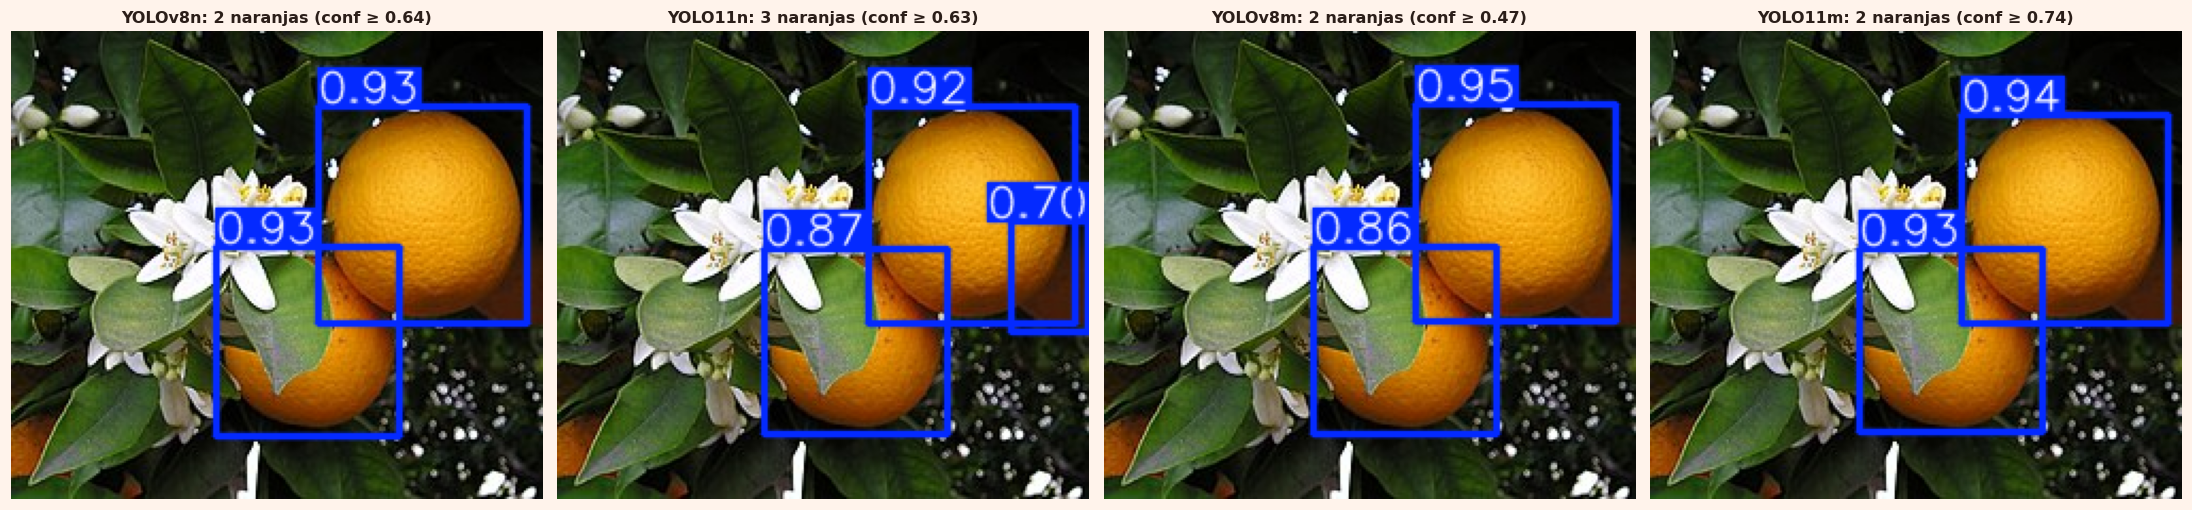

In [40]:
# 9.2 Subir imágenes y detectar naranjas
COMPARAR_TODOS = True
IMAGENES_LOCALES = ['naranjas.jpg']   # Solo se usa fuera de Colab

if EN_COLAB:
    from google.colab import files
    rutas = list(files.upload())     # Guarda las fotos subidas en /content
else:
    rutas = [r for r in IMAGENES_LOCALES if Path(r).exists()]
    if not rutas:
        print('No se encontró ninguna imagen en IMAGENES_LOCALES; se usa una de test como ejemplo.')
        rutas = [ruta_imagen(test_tabla['archivo'].iloc[0], 'test')] if 'test_tabla' in globals() else []

for ruta in rutas:
    mostrar_detecciones(ruta, comparar=COMPARAR_TODOS)

### 9.3 Webcam en tiempo real (solo en tu computadora)
Colab se ejecuta en un servidor remoto y no puede abrir una ventana de video. En tu computadora (Jupyter o VS Code), pon `USAR_WEBCAM = True`.
Se abre una ventana con las naranjas detectadas, el conteo y los FPS. Pulsa **q** o **ESC** para salir.

In [41]:
# 9.3 Detección en vivo con la webcam
USAR_WEBCAM = False
CAMARA = 0   # Si tienes varias cámaras, prueba 1 o 2


def detectar_en_webcam(tipo=None, camara=0):
    tipo = tipo or MODELO_FINAL
    modelo, umbral = modelos_listos[tipo], UMBRALES[tipo]
    cap = cv2.VideoCapture(camara)
    if not cap.isOpened():
        print(f'No se pudo abrir la cámara {camara}.')
        return
    anterior = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            r = modelo.predict(frame, conf=umbral, imgsz=IMGSZ, verbose=False)[0]
            frame = r.plot(labels=False)
            ahora = time.time()
            fps, anterior = 1 / max(ahora - anterior, 1e-6), ahora
            cv2.rectangle(frame, (0, 0), (330, 70), (0, 0, 0), -1)
            cv2.putText(frame, f'{tipo}  FPS: {fps:.1f}', (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            cv2.putText(frame, f'Naranjas: {len(r.boxes)}', (10, 58), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 165, 255), 2)
            cv2.imshow('Orange Vision', frame)
            if cv2.waitKey(1) & 0xFF in (ord('q'), 27):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()


if USAR_WEBCAM and not EN_COLAB:
    detectar_en_webcam(camara=CAMARA)
elif USAR_WEBCAM:
    print('En Colab usa la celda 9.4 para tomar una foto con la cámara del navegador.')

### 9.4 Foto con la cámara del navegador (Colab)
En Colab sí se puede tomar **una foto** con la cámara de tu navegador. Pon `TOMAR_FOTO = True`, ejecuta la celda y pulsa el botón que aparece.

In [42]:
# 9.4 Tomar una foto en Colab y detectar naranjas
TOMAR_FOTO = True

if TOMAR_FOTO and EN_COLAB:
    import base64
    from IPython.display import Javascript, display
    from google.colab.output import eval_js

    display(Javascript("""
    async function tomarFoto(calidad) {
      const div = document.createElement('div');
      const boton = document.createElement('button');
      boton.textContent = 'Tomar foto';
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(boton);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      await new Promise((resolve) => boton.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', calidad);
    }
    """))
    datos = eval_js('tomarFoto(0.9)')
    Path('foto_webcam.jpg').write_bytes(base64.b64decode(datos.split(',')[1]))
    mostrar_detecciones('foto_webcam.jpg', comparar=True)
elif TOMAR_FOTO:
    print('Esta celda es para Colab. En tu computadora usa la celda 9.3.')

<IPython.core.display.Javascript object>

MessageError: NotFoundError: Requested device not found

---
## 10. Glosario rápido

| Término | Significado breve |
|---|---|
| Neurona / peso | Unidad que multiplica entradas por pesos, suma y aplica una activación. Los pesos son lo que se aprende |
| CNN | Red que usa filtros que se deslizan por la imagen (convolución) para extraer características |
| Feature map | Resultado de aplicar un filtro: un "mapa" de dónde aparece cierta característica |
| Backbone / neck / head | Extraer características / combinar escalas / predecir cajas y clases |
| Transformer / atención | Arquitectura donde cada parte de la entrada pondera a todas las demás (contexto global) |
| YOLO | Detector de una etapa: predice todas las cajas en una sola pasada |
| YOLOv8 / YOLO11 | Versiones de YOLO de Ultralytics (2023 / 2024); *n* = nano, *m* = medium |
| C2f / C3k2 | Bloque principal de YOLOv8 / su versión más ligera en YOLO11 |
| C2PSA | Bloque de atención de YOLO11 al final del backbone |
| *Anchor-free* | Predecir el centro y tamaño del objeto sin cajas de referencia predefinidas |
| Preentrenado / COCO | Modelo ya entrenado en un dataset grande (COCO: 118k imágenes, 80 clases) |
| Etapa Pura | Usar el modelo de COCO tal cual, sin entrenarlo con nuestras fotos |
| Transfer learning | Reutilizar lo aprendido en una tarea para otra. En sentido estricto (*feature extraction*): backbone congelado, solo se entrenan neck y head |
| Fine-tuning | Seguir entrenando **toda** la red preentrenada con datos propios y un *learning rate* pequeño |
| Olvido catastrófico | Perder lo aprendido en COCO por actualizar los pesos con pasos demasiado grandes |
| *Domain shift* | Diferencia entre los datos con los que se entrenó (COCO) y los datos de uso (naranjas de campo) |
| Congelar capas | Impedir que ciertos pesos cambien durante el entrenamiento |
| Función de pérdida | Número que mide cuánto se equivoca el modelo; el entrenamiento lo minimiza |
| box / cls / dfl loss | Pérdida de la caja (CIoU) / de la clase (entropía cruzada binaria) / de la precisión fina de los bordes |
| Gradiente / retropropagación | Dirección en que cambiar cada peso / algoritmo que la calcula |
| Learning rate | Tamaño del paso al actualizar los pesos |
| Warmup | Empezar con un learning rate pequeño e ir subiéndolo |
| Optimizador (AdamW) | Regla para actualizar los pesos a partir del gradiente |
| Batch / iteración / época | Imágenes por actualización / una actualización / una pasada por todo train |
| Sobreajuste | Memorizar train en lugar de generalizar |
| Early stopping / paciencia | Parar cuando validación deja de mejorar / cuántas épocas esperar |
| Aumento de datos | Modificaciones aleatorias de las imágenes de train |
| Semilla | Número que fija el azar para poder repetir un experimento |
| AMP | Usar números de 16 bits para entrenar más rápido |
| Train / val / test | Aprender / decidir / medir el resultado final |
| Fuga de datos | Que información del test se cuele en el entrenamiento |
| IoU | Solapamiento entre dos cajas (intersección / unión) |
| NMS | Eliminar cajas duplicadas del mismo objeto |
| TP / FP / FN | Acierto / falsa alarma / objeto no detectado |
| Matriz de confusión (detección) | Tabla con TP, FN y FP contando cajas; no tiene verdaderos negativos |
| Precisión / recall / F1 | Calidad de las detecciones / cobertura de objetos / equilibrio |
| mAP50 / mAP50-95 | Área bajo la curva precisión-recall con IoU 0.5 / promediada entre IoU 0.5 y 0.95 |
| Umbral de confianza | Confianza mínima para aceptar una detección |
| Curva PR / curva F1 | Precisión según el recall / F1 según el umbral de confianza |
| Frontera de Pareto | Modelos que ningún otro supera a la vez en velocidad y en precisión |
| Parámetros / GFLOPs | Tamaño del modelo / coste de cálculo por imagen |
| Latencia / FPS | Tiempo por imagen / imágenes por segundo |
| Acumulación de gradiente / `nbs` | Sumar los gradientes de varios batches antes de actualizar los pesos, para simular un batch de `nbs` imágenes |
| Dataset pequeño | Pocas fotos de train: más riesgo de sobreajuste y métricas de test poco fiables |
| Generalización entre datasets | Cómo funciona un modelo con fotos de otro dataset (otra cámara, huerto o luz) sin reentrenarlo |
| Semilla | Número que fija el azar del entrenamiento; repetir con varias semillas mide cuánto cambia el resultado por azar |